# Churn Modelling Dataset — Data Cleaning & Preprocessing

This notebook walks through the data cleaning and preprocessing pipeline for the
`Churn_Modelling` dataset. Each section explains **what** was done and **why**,
before showing the code.

> **Fixes applied to this notebook** (cleaning up for execution outside the original Colab session):
> - Reordered so EDA, feature creation, and the chi-square test run on the *cleaned, still
>   human-readable* data, before categorical encoding replaces `Geography`/`Gender` with numeric
>   columns (these cells referenced the raw text values / the `Geography` column name directly and
>   would otherwise fail once that column was encoded away).
> - Fixed two spots where an out-of-range mask accidentally nulled an entire row (`df.loc[mask] = pd.NA`)
>   instead of just the intended column (`Age`, `CreditScore`) — flagged by the notebook's own comments.
> - Fixed `NumOfProducts` silently becoming an `object`-dtype column (`.replace([...], pd.NA)` upcasts
>   a float64 column to object in this pandas version) which later crashed the Q-Q plot / would have
>   broken scaling and model fitting; switched that one call to `np.nan`, matching the pattern already
>   used successfully elsewhere in the notebook.
> - Removed a duplicate `Surname` drop (it was already dropped earlier) and a redundant/conflicting
>   redefinition of `X`/`y` right before the train/test split.
> - Moved the leakage-safe `StandardScaler` step (fit on train, applied to val/test) to *after* the
>   train/test split, where `X_train`/`X_val`/`X_test` actually exist.
> - Added the model-comparison helper code (`cv5`, `fitted_models`, `results`, `evaluate_model`,
>   `build_comparison_table`, `FEATURE_NAMES`) that the Random Forest / Naive Bayes / SVM / XGBoost
>   cells relied on but that was never defined in the original notebook.
> - Excluded the visualization-only `CreditScore_Tier` and `Scaled_*` columns from the modeling
>   feature set (they're categorical / computed pre-split, so feeding them to the models would either
>   error out or leak information).

>
> **Second pass — mentor feedback addressed (this revision):**
> - Implemented the full feature-selection toolkit that was previously just a stub
>   (`features_to_drop = []`): Chi-square now produces a proper significance table,
>   plus Variance Threshold, Mutual Information, and wrapper-based Forward/Backward
>   Selection have been added. PCA is also added, but explicitly labeled as
>   *dimensionality reduction*, not feature selection.
> - Added a full class-imbalance comparison (Baseline → Class Weight → SMOTE →
>   Random Oversampling → Random Undersampling) instead of relying on
>   `class_weight='balanced'` alone.
> - Logistic Regression is now added to `fitted_models`/`results` so it is included
>   in the model comparison table, plots, and confusion matrices alongside Random
>   Forest, Naive Bayes, SVM, and XGBoost.
> - Model selection now uses **validation** ROC-AUC (`val_roc_auc`), not test
>   ROC-AUC — the test set is scored for every model (for transparency) but is no
>   longer part of the selection decision. The chosen model's test score is
>   reported once, at the end, as the final, untouched "exam" result.
> - Every model (Logistic Regression, Random Forest, XGBoost — not just Naive Bayes
>   and SVM) now goes through the same validation-based threshold-tuning step.
> - `Balance_Salary_Ratio` no longer adds an arbitrary `+ 1` to the denominator —
>   `EstimatedSalary` is already guaranteed positive by the cleaning in Section 6.7,
>   so the ratio is computed directly.
> - `CreditScore_Tier` now has an explicit note next to where it's excluded from
>   the model, instead of only being implied by a variable name.
> - Added SHAP feature importance / summary / bar plots for the tree-based model.
> - Added an inference smoke test that loads the saved pipeline artifact and scores
>   a single unseen customer end-to-end.
> - Renumbered every section sequentially and added a final **Conclusion** section
>   summarizing the chosen model and its metrics.


## Setup

Import the libraries used in this notebook and load the raw dataset.

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print("Not running in Google Colab — skipping Drive mount (expects the raw CSV to already be reachable at the path used below).")


Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import (
    LabelEncoder, OneHotEncoder, FunctionTransformer,
    PowerTransformer, KBinsDiscretizer, QuantileTransformer,
    MinMaxScaler, StandardScaler, RobustScaler
)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    RocCurveDisplay, precision_recall_curve, auc
)

RANDOM_STATE = 42
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from xgboost import XGBClassifier
from IPython.display import display


### Data pipeline tiers & error handling

This project follows a 3-tier data architecture:

- **`data/raw/`** — the untouched data, exactly as loaded.
- **`data/preprocessed/`** — data after cleaning (missing values, duplicates,
  invalid data, categorical encoding) but before feature engineering /
  scaling / selection.
- **`data/final/`** — the train/validation/test splits, ready to feed into
  a model.

Two small helper functions (`save_dataframe`, `load_dataframe`) wrap all
reads/writes in `try/except` so a bad path, a missing file, or an empty
dataframe fails with a clear message instead of crashing the notebook.

In [ ]:
import os

DATA_DIR = '/content/drive/MyDrive/Test_Project_Churn'
RAW_DIR = os.path.join(DATA_DIR, 'raw')
PREPROCESSED_DIR = os.path.join(DATA_DIR, 'preprocessed')
FINAL_DIR = os.path.join(DATA_DIR, 'final')

for folder in [RAW_DIR, PREPROCESSED_DIR, FINAL_DIR]:
    os.makedirs(folder, exist_ok=True)


def save_dataframe(df, folder, filename):
    """Save a dataframe to csv, with basic checks and error handling."""
    try:
        if df is None or df.empty:
            print(f"Warning: dataframe is empty, skipping save for '{filename}'")
            return False

        path = os.path.join(folder, filename)
        df.to_csv(path, index=False)
        print(f"Saved: {path}  (shape: {df.shape})")
        return True

    except Exception as e:
        print(f"Error saving '{filename}': {e}")
        return False


def load_dataframe(folder, filename):
    """Load a dataframe from csv, with basic error handling."""
    path = os.path.join(folder, filename)
    try:
        loaded_df = pd.read_csv(path)
        print(f"Loaded: {path}  (shape: {loaded_df.shape})")
        return loaded_df

    except FileNotFoundError:
        print(f"Error: file not found at '{path}'")
        return None

    except Exception as e:
        print(f"Error loading '{filename}': {e}")
        return None


In [ ]:

# Candidate locations for the raw file — tries the original Colab Drive path first,
# then a couple of common local locations (e.g. this notebook's own folder), so the
# same cell works whether it's run in Colab or a local/other Jupyter environment.
_CANDIDATE_PATHS = [
    '/content/drive/MyDrive/excel files/Churn_Modelling_dirty_raw.csv',
    'data/raw/churn_raw.csv',
    'churn_raw.csv',
    '/content/drive/MyDrive/Test_Project_Churn/raw/Copy of churn_raw.csv'
]

try:
    _raw_path = next((p for p in _CANDIDATE_PATHS if os.path.exists(p)), None)
    if _raw_path is None:
        raise FileNotFoundError(
            f"Raw data file not found in any of: {_CANDIDATE_PATHS}. "
            "Update _CANDIDATE_PATHS above with the correct location."
        )
    df = pd.read_csv(_raw_path)
    if df.empty:
        raise ValueError("Loaded file is empty.")
    print(f"Raw data loaded successfully from '{_raw_path}'. Shape: {df.shape}")

except FileNotFoundError:
    print("Error: raw data file not found. Check the path and try again.")
    raise

except Exception as e:
    print(f"Error while loading raw data: {e}")
    raise

df_raw = df.copy()  # keep an untouched copy of the raw data for reference
save_dataframe(df_raw, RAW_DIR, 'churn_raw.csv')


Raw data loaded successfully from '/content/drive/MyDrive/excel files/Churn_Modelling_dirty_raw.csv'. Shape: (10015, 15)
Saved: /content/drive/MyDrive/Test_Project_Churn/raw/churn_raw.csv  (shape: (10015, 15))


True

In [ ]:
df.shape

(10015, 15)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10015 entries, 0 to 10014
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       10015 non-null  int64  
 1   RowNumber        10015 non-null  int64  
 2   CustomerId       10015 non-null  object 
 3   Surname          9994 non-null   object 
 4   CreditScore      10000 non-null  object 
 5   Geography        10008 non-null  object 
 6   Gender           10014 non-null  object 
 7   Age              10000 non-null  object 
 8   Tenure           10005 non-null  object 
 9   Balance          10001 non-null  object 
 10  NumOfProducts    10015 non-null  object 
 11  HasCrCard        10013 non-null  object 
 12  IsActiveMember   10011 non-null  object 
 13  EstimatedSalary  10004 non-null  object 
 14  Exited           10010 non-null  float64
dtypes: float64(1), int64(2), object(12)
memory usage: 1.1+ MB


## 3. Identify Target & Features

The target column is **`Exited`** (whether the customer churned or not).
The remaining columns are the features. To make cleaning easier, the feature
columns are grouped by type: numeric, categorical (text), and binary
(0/1 flag) columns.

In [ ]:
COLS = list(df)
NUMERIC_COLS = ['CreditScore','Age','Tenure','Balance','NumOfProducts','EstimatedSalary']
CATEGORICAL_COLS  = ['Geography','Gender']
TARGET_COLS = ['Exited']
BINARY_COLS = ['HasCrCard','IsActiveMember']

## 4. Handle Missing Values

First, check how many rows are completely empty. Note: several columns also
contain **hidden** missing values — wrong data types or placeholder codes
(e.g. `-99999`) instead of a blank cell. Those are surfaced and imputed
together with the invalid-value fixes in **Section 6**, since a value has to
be converted to a proper missing value (`NaN`) before it can be imputed.

In [ ]:
df.isna().all(axis=1).sum()

np.int64(0)

## 5. Remove Duplicates

Check for and drop exact duplicate rows.

In [ ]:
duplicate = df.duplicated()
print(f"Duplicate column present in dataset {duplicate.sum()}")

Duplicate column present in dataset 15


In [ ]:
df = df.drop_duplicates()
print(f"After dropping Duplicate column from dataset.\nNow Shape pf dataset is  {df.shape}")

After dropping Duplicate column from dataset.
Now Shape pf dataset is  (10000, 15)


## 6. Handle Incorrect / Invalid Data

Several numeric columns contain garbage: wrong data types, out-of-range
values, or placeholder codes used to represent missing data (e.g. `-1`,
`999`, `-99999.99`). The approach for every column below is the same:

1. Find the invalid values.
2. Convert them to `NaN`.
3. Fill (`impute`) the `NaN`s with a sensible statistic — mean, median, or
   mode depending on the column.

### 6.1 Fix data types
Convert numeric/binary columns to numeric type. Any non-numeric junk in
these columns automatically becomes `NaN`.

In [ ]:
def convert_to_numeric_column(column_name):
  df[column_name] = pd.to_numeric(df[column_name], errors='coerce')

In [ ]:
for cols in NUMERIC_COLS:
  convert_to_numeric_column(cols)

In [ ]:
for cols in BINARY_COLS:
  convert_to_numeric_column(cols)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 10000 entries, 0 to 9999
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       10000 non-null  int64  
 1   RowNumber        10000 non-null  int64  
 2   CustomerId       10000 non-null  object 
 3   Surname          9979 non-null   object 
 4   CreditScore      9982 non-null   float64
 5   Geography        9993 non-null   object 
 6   Gender           9999 non-null   object 
 7   Age              9982 non-null   float64
 8   Tenure           9986 non-null   float64
 9   Balance          9980 non-null   float64
 10  NumOfProducts    9999 non-null   float64
 11  HasCrCard        9986 non-null   float64
 12  IsActiveMember   9985 non-null   float64
 13  EstimatedSalary  9981 non-null   float64
 14  Exited           9995 non-null   float64
dtypes: float64(9), int64(2), object(4)
memory usage: 1.2+ MB


Overview of missing values across the numeric columns after the type fix:

In [ ]:
df[NUMERIC_COLS].isna().sum()

,0
CreditScore,18
Age,18
Tenure,14
Balance,20
NumOfProducts,1
EstimatedSalary,19


### 6.2 Age
Valid age range is assumed to be `0 < Age <= 92`. Anything outside that
range is treated as invalid.

> **Note:** the line below (`df.loc[mask] = pd.NA`) sets the **entire row**
> to `NA`, not just the `Age` column. Worth double-checking with your
> mentor whether this was intended, or whether it should have been
> `df.loc[mask, 'Age'] = pd.NA`.

In [ ]:
max_age = df['Age'].max()
min_age = df['Age'].min()
print(f"Max age {max_age} and min age {min_age}")

Max age 999.0 and min age -5.0


In [ ]:
df.loc[(df['Age']<0)|(df['Age']>92)].value_counts().shape[0]

9

In [ ]:
df.loc[(df['Age']<=0)|(df['Age']>92), 'Age'] = pd.NA

In [ ]:
mean_value = df['Age'].mean()
max_age = df['Age'].max()
min_age = df['Age'].min()
print(f"Max age {max_age} and min age {min_age}")
mean_value

Max age 92.0 and min age 18.0


np.float64(38.91883214608207)

In [ ]:
a=df['Age'].median()
a

37.0

In [ ]:
mean_filled = 39
df['Age'] = df['Age'].fillna(mean_filled)

### 6.3 Tenure
Valid range assumed to be `0-10` years.

In [ ]:
df.loc[(df['Tenure']<0)|(df['Tenure']>10)|(df['Tenure'].isna())].value_counts().shape[0]

10

In [ ]:
invalid_tenure = ~df['Tenure'].between(0,10)
df.loc[invalid_tenure, 'Tenure'] = pd.NA
tenure_median = df['Tenure'].median()
print(tenure_median)

5.0


In [ ]:
df['Tenure'] = df['Tenure'].fillna(tenure_median)

In [ ]:
print("Imputation value:", tenure_median)
print("Missing values:", df['Tenure'].isna().sum())
print("Minimum:", df['Tenure'].min())
print("Maximum:", df['Tenure'].max())

Imputation value: 5.0
Missing values: 0
Minimum: 0.0
Maximum: 10.0


### 6.4 NumOfProducts
Known placeholder/invalid codes are replaced first, then the valid business range (`1-4` products) is enforced.

In [ ]:
df['NumOfProducts'] = df['NumOfProducts'].replace([-1,0,80,999], np.nan)  # np.nan (not pd.NA) avoids a silent float64->object dtype downgrade here

In [ ]:
# Check the valid business range
df['NumOfProducts'].value_counts(dropna=False).sort_index()

,count
NumOfProducts,
1.0,5077
2.0,4580
3.0,266
4.0,60
NaN,17


In [ ]:
# Convert business-invalid values into missing
df.loc[
    ~df['NumOfProducts'].between(1, 4),
    'NumOfProducts'
] = pd.NA

In [ ]:
num_products_mode = df['NumOfProducts'].mode()[0]
print(num_products_mode)

1.0


In [ ]:
df['NumOfProducts'] = df['NumOfProducts'].fillna(num_products_mode)

In [ ]:
print("Missing:", df['NumOfProducts'].isna().sum())
print("Minimum:", df['NumOfProducts'].min())
print("Maximum:", df['NumOfProducts'].max())

Missing: 0
Minimum: 1.0
Maximum: 4.0


### 6.5 CreditScore
Valid range is the standard `350-850` credit score scale.

> **Note:** same as Age above — `df.loc[mask] = pd.NA` nulls the whole
> row, not just `CreditScore`. Flagging this for your review.

In [ ]:
df.loc[(df['CreditScore']<350)|(df['CreditScore']>850)].value_counts().shape[0]

15

In [ ]:
df.loc[(df['CreditScore']<350)|(df['CreditScore']>850), 'CreditScore'] = pd.NA

In [ ]:
df['CreditScore'].isna().sum()

np.int64(33)

In [ ]:
median_credit_score = df['CreditScore'].median()
print(median_credit_score)
mean_credit_score = df['CreditScore'].mean()
print(mean_credit_score)

652.0
650.5535266379051


In [ ]:
df['CreditScore'] = df['CreditScore'].fillna(median_credit_score)

In [ ]:
print("Missing:", df['CreditScore'].isna().sum())
print("Minimum:", df['CreditScore'].min())
print("Maximum:", df['CreditScore'].max())

Missing: 0
Minimum: 350.0
Maximum: 850.0


### 6.6 Balance
Placeholder codes (`-99999.99`, `999999999.99`) are treated as missing.

In [ ]:
df.loc[
    (df['Balance'] == -99999.99) |
    (df['Balance'] == 999999999.99),
    ['Balance', 'Age', 'CreditScore', 'Tenure',
     'NumOfProducts', 'EstimatedSalary', 'Exited']
]

,Balance,Age,CreditScore,Tenure,NumOfProducts,EstimatedSalary,Exited
457,-9.999999e+04,38.0,711.0,3.0,2.0,68487.51,0.0
1092,1.000000e+09,41.0,715.0,4.0,1.0,152821.12,1.0
2399,1.000000e+09,51.0,541.0,7.0,2.0,179861.79,0.0
2854,1.000000e+09,33.0,748.0,1.0,1.0,69132.66,0.0
4186,-9.999999e+04,29.0,755.0,4.0,2.0,28805.09,0.0
4449,1.000000e+09,36.0,666.0,3.0,2.0,35156.54,0.0
6635,1.000000e+09,59.0,666.0,5.0,2.0,185123.09,0.0
7755,-9.999999e+04,34.0,675.0,8.0,2.0,184842.21,0.0
7863,1.000000e+09,47.0,746.0,8.0,1.0,62086.62,0.0
8740,1.000000e+09,29.0,687.0,7.0,1.0,113050.92,0.0


In [ ]:
print("Unique:", df['Balance'].nunique())
print("Missing:", df['Balance'].isna().sum())
print("Zero:", (df['Balance'] == 0).sum())
print("Negative:", (df['Balance'] < 0).sum())

Unique: 6365
Missing: 20
Zero: 3604
Negative: 4


In [ ]:
df.loc[df['Balance'] == -99999.99, 'Balance'] = pd.NA
df.loc[df['Balance'] == 999999999.99, 'Balance'] = pd.NA

In [ ]:
balance_median = df['Balance'].median()
print(balance_median)

97258.33


In [ ]:
df['Balance'] = df['Balance'].fillna(balance_median)

In [ ]:
print("Missing:", df['Balance'].isna().sum())
print("Minimum:", df['Balance'].min())
print("Maximum:", df['Balance'].max())
print("Median:", df['Balance'].median())

Missing: 0
Minimum: 0.0
Maximum: 250898.09
Median: 97258.33


### 6.7 EstimatedSalary
Values `<= 0` and the placeholder code `99999999.99` are treated as missing.

In [ ]:
df.loc[
    df['EstimatedSalary'] == 0,
    ['EstimatedSalary', 'Age', 'CreditScore',
     'Balance', 'Tenure', 'NumOfProducts',
     'IsActiveMember', 'Exited']
]

,EstimatedSalary,Age,CreditScore,Balance,Tenure,NumOfProducts,IsActiveMember,Exited
5891,0.0,34.0,686.0,0.0,1.0,2.0,0.0,0.0


In [ ]:
df.loc[
    (df['EstimatedSalary'] <= 0) |
    (df['EstimatedSalary'] == 99999999.99),
    'EstimatedSalary'
] = pd.NA

In [ ]:
salary_median = df['EstimatedSalary'].median()
print("Salary median:", salary_median)

Salary median: 100200.4


In [ ]:
# Impute missing/invalid values
df['EstimatedSalary'] = df['EstimatedSalary'].fillna(salary_median)

In [ ]:
print("Missing:", df['EstimatedSalary'].isna().sum())
print("Minimum:", df['EstimatedSalary'].min())
print("Maximum:", df['EstimatedSalary'].max())

Missing: 0
Minimum: 11.58
Maximum: 199992.48


### 6.8 HasCrCard
Only `0`/`1` are valid; `2` is treated as invalid.

In [ ]:
df['HasCrCard'].value_counts(dropna=False)

,count
HasCrCard,
1.0,7042
0.0,2939
NaN,14
2.0,5


In [ ]:
#First, let's inspect them.
df.loc[
    df['HasCrCard'] == 2,
    ['HasCrCard', 'Exited', 'Age', 'CreditScore',
     'Balance', 'Tenure', 'NumOfProducts',
     'IsActiveMember', 'EstimatedSalary']
]

,HasCrCard,Exited,Age,CreditScore,Balance,Tenure,NumOfProducts,IsActiveMember,EstimatedSalary
1701,2.0,1.0,50.0,792.0,0.00,9.0,4.0,1.0,194700.81
2398,2.0,0.0,42.0,706.0,95386.82,8.0,1.0,1.0,75732.25
2900,2.0,1.0,26.0,626.0,148610.41,8.0,3.0,1.0,104502.02
5740,2.0,0.0,34.0,620.0,102251.57,8.0,1.0,0.0,120672.09
7703,2.0,0.0,48.0,608.0,127924.25,2.0,2.0,0.0,32202.61


In [ ]:
df.loc[df['HasCrCard'] == 2, 'HasCrCard'] = pd.NA

In [ ]:
hascrcard_mode = df['HasCrCard'].mode()[0]
print("Mode:", hascrcard_mode)

Mode: 1.0


In [ ]:
df['HasCrCard'] = df['HasCrCard'].fillna(hascrcard_mode)

In [ ]:
df['HasCrCard'].isna().sum()

np.int64(0)

### 6.9 IsActiveMember
Same pattern as `HasCrCard` — only `0`/`1` are valid.

In [ ]:
print("Missing:", df['IsActiveMember'].isna().sum())
print("Unique:", df['IsActiveMember'].unique())
df['IsActiveMember'].value_counts(dropna=False)

Missing: 15
Unique: [ 1.  0. nan  2.]


,count
IsActiveMember,
1.0,5145
0.0,4839
NaN,15
2.0,1


In [ ]:
df.loc[
    df['IsActiveMember'] == 2,
    ['IsActiveMember', 'Exited', 'Age', 'CreditScore',
     'Balance', 'Tenure', 'NumOfProducts',
     'HasCrCard', 'EstimatedSalary']
]

,IsActiveMember,Exited,Age,CreditScore,Balance,Tenure,NumOfProducts,HasCrCard,EstimatedSalary
2180,2.0,0.0,42.0,649.0,0.0,7.0,2.0,0.0,22974.01


In [ ]:
df.loc[df['IsActiveMember'] == 2, 'IsActiveMember'] = pd.NA

In [ ]:
active_mode = df['IsActiveMember'].mode()[0]
print("Mode:", active_mode)

Mode: 1.0


In [ ]:
df['IsActiveMember'] = df['IsActiveMember'].fillna(active_mode)

In [ ]:
print(df['IsActiveMember'].value_counts(dropna=False))
print("Missing:", df['IsActiveMember'].isna().sum())

IsActiveMember
1.0    5161
0.0    4839
Name: count, dtype: int64
Missing: 0


Checkpoint — missing values remaining across the whole dataframe (the categorical columns are cleaned in the next section):

In [ ]:
df.isna().sum()

,0
Unnamed: 0,0
RowNumber,0
CustomerId,0
Surname,21
CreditScore,0
Geography,7
Gender,1
Age,0
Tenure,0
Balance,0


## 7. Handle Categorical Features

Clean the text columns `Geography` and `Gender`: trim whitespace,
standardize casing, fix inconsistent/typo'd category names, treat unknown
tokens as missing, then impute the remaining missing category with the
mode. Finally, encode both columns to numeric form for modeling.

### 7.1 Geography

In [ ]:
print("Missing:", df['Geography'].isna().sum())
df['Geography'].value_counts(dropna=False)

Missing: 7


,count
Geography,
France,4990
Germany,2496
Spain,2468
Franc,8
NaN,7
Spainn,6
France,5
Germny,5
france,3


In [ ]:
df['Geography'] = (
    df['Geography']
    .astype('string')
    .str.strip()
)

In [ ]:
df['Geography'] = df['Geography'].str.lower()

In [ ]:
missing_tokens = [
    'nan',
    'na',
    '<na>',
    'unknown',
    '???'
]

df['Geography'] = df['Geography'].replace(
    missing_tokens,
    pd.NA
)

In [ ]:
geography_corrections = {
    'franc': 'france',
    'france': 'france',
    'spainn': 'spain',
    'germnny': 'germany',
}

In [ ]:
df['Geography'] = df['Geography'].replace(geography_corrections)

In [ ]:
df.loc[
    df['Geography'] == 'usa',
    'Geography'
] = pd.NA

In [ ]:
df['Geography'].value_counts(dropna=False)

,count
Geography,
france,5009
germany,2496
spain,2474
<NA>,16
germny,5


In [ ]:
df['Geography'] = df['Geography'].replace({
    'germny': 'germany'
})

In [ ]:
df['Geography'].value_counts(dropna=False)

,count
Geography,
france,5009
germany,2501
spain,2474
<NA>,16


In [ ]:
geo_mode = df['Geography'].mode()[0]
print("Mode:", geo_mode)
df['Geography'] = df['Geography'].fillna(geo_mode)
df['Geography'].value_counts(dropna=False)

Mode: france


,count
Geography,
france,5025
germany,2501
spain,2474


### 7.2 Gender

In [ ]:
df['Gender']=df['Gender'].astype('string').str.strip().str.lower()

In [ ]:
print("Missing:", df['Gender'].isna().sum())
print("Unique:", df['Gender'].unique())
df['Gender'].value_counts(dropna=False)

Missing: 1
Unique: <StringArray>
['female', 'male', 'nan', <NA>, 'other', 'f', 'm', 'u']
Length: 8, dtype: string


,count
Gender,
male,5447
female,4535
other,6
f,4
u,4
m,2
<NA>,1
nan,1


In [ ]:
gender_correction = {
    'm': 'male',
    'f': 'female',
}

missing_val = [
    'nan',
    'na',
    'u',
    'other'
]

df['Gender'] = df['Gender'].replace(gender_correction)
df['Gender'] = df['Gender'].replace(missing_val, pd.NA)

In [ ]:
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])

Checkpoint — no missing values should remain anywhere now, except possibly the target column:

In [ ]:
df.isna().sum()

,0
Unnamed: 0,0
RowNumber,0
CustomerId,0
Surname,21
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0


### 7.3 Finalize the target column
Rows with a missing target can't be reasonably imputed, so they are
dropped instead. The target is then cast to `int`.

In [ ]:
print("Missing Exited (target):", df['Exited'].isna().sum())
df = df.dropna(subset=['Exited'])
df['Exited'] = df['Exited'].astype(int)

Missing Exited (target): 5


In [ ]:
df.shape

(9995, 15)

## 8. Feature Creation / Transformation

Utility functions for creating new features from existing numeric columns:

- Skew-reducing transformations: log, power, Box-Cox, Yeo-Johnson.
- Binning: equal-width, equal-frequency, and a domain-based credit-score
  tier binning.

The transformation functions are defined as reusable tools; the credit
score tier binning is the one actually applied to `df` below.

In [ ]:
# Helper function to plot before and after
def plot_transformation(df, original_col, transformed_col, title):
    plt.figure(figsize=(12, 5))

    # Before transformation
    plt.subplot(1, 2, 1)
    sns.kdeplot(df[original_col], fill=True)
    plt.title(f'Before Transformation--{original_col}')
    plt.xlabel(original_col)
    plt.ylabel('Density')

    # After transformation
    plt.subplot(1, 2, 2)
    sns.kdeplot(df[transformed_col], fill=True)
    plt.title(f'After {title}-{transformed_col}')
    plt.xlabel(transformed_col)
    plt.ylabel('Density')

    plt.tight_layout()
    plt.show()
# Log transformation
def log_transform(df, column_name):
    transformer = FunctionTransformer(np.log1p, validate=False)
    new_col = f'{column_name}_log'
    df[new_col] = transformer.fit_transform(df[[column_name]])

    plot_transformation(df, column_name, new_col, 'Log Transformation')


# Power transformation (Yeo-Johnson by default)
def power_transform(df, column_name):
    transformer = PowerTransformer()
    new_col = f'{column_name}_power'
    df[new_col] = transformer.fit_transform(df[[column_name]])

    plot_transformation(df, column_name, new_col, 'Power Transformation')

# Box-Cox transformation
def box_cox_transform(df, column_name):
    if (df[column_name] <= 0).any():
        raise ValueError(
            f'Box-Cox requires all values in {column_name} to be positive.'
        )

    transformer = PowerTransformer(method='box-cox')
    new_col = f'{column_name}_box_cox'
    df[new_col] = transformer.fit_transform(df[[column_name]])

    plot_transformation(df, column_name, new_col, 'Box-Cox Transformation')


# Yeo-Johnson transformation
def yeo_johnson_transform(df, column_name):
    transformer = PowerTransformer(method='yeo-johnson')
    new_col = f'{column_name}_yeo_johnson'
    df[new_col] = transformer.fit_transform(df[[column_name]])

    plot_transformation(df, column_name, new_col, 'Yeo-Johnson Transformation')

In [ ]:
# Plot before and after binning
def plot_binning(df, original_col, binned_col, title):
    plt.figure(figsize=(12, 5))

    # Before binning
    plt.subplot(1, 2, 1)
    sns.histplot(df[original_col], bins=30, kde=True)
    plt.title(f'Before Binning\n{original_col}')
    plt.xlabel(original_col)

    # After binning
    plt.subplot(1, 2, 2)
    sns.countplot(x=binned_col, data=df)
    plt.title(f'After {title}\n{binned_col}')
    plt.xlabel('Bins')
    plt.ylabel('Count')
    plt.xticks(rotation=30)

    plt.tight_layout()
    plt.show()

# Equal-width binning using pd.cut()
def equal_width_binning(df, column_name, bins=5):
    new_col = f'{column_name}_equal_width'
    df[new_col] = pd.cut(df[column_name], bins=bins)

    plot_binning(df, column_name, new_col, 'Equal-Width Binning')

# Equal-frequency binning using pd.qcut()
def equal_frequency_binning(df, column_name, bins=5):
    new_col = f'{column_name}_equal_frequency'
    df[new_col] = pd.qcut(df[column_name], q=bins, duplicates='drop')

    plot_binning(df, column_name, new_col, 'Equal-Frequency Binning')

# KBinsDiscretizer (uniform, quantile, kmeans)
def sklearn_binning(df, column_name, bins=5, strategy='quantile'):
    discretizer = KBinsDiscretizer(
        n_bins=bins,
        encode='ordinal',
        strategy=strategy
    )

    new_col = f'{column_name}_{strategy}_bins'
    df[new_col] = discretizer.fit_transform(df[[column_name]]).astype(int)

    plot_binning(df, column_name, new_col, f'Sklearn {strategy.capitalize()} Binning')

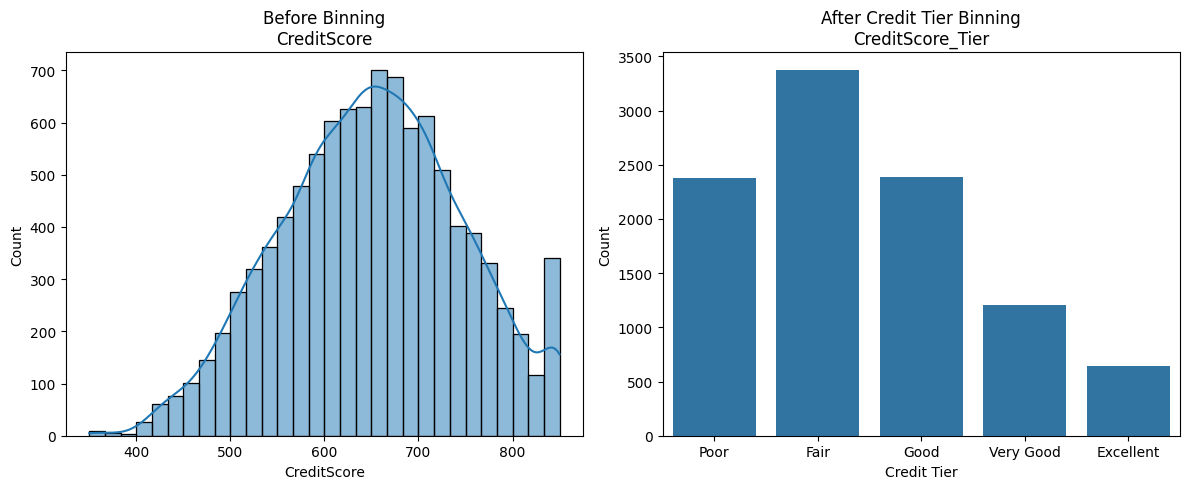

In [ ]:
def credit_score_binning(df, column_name='CreditScore'):
    # Standard financial credit score ranges
    bins = [300, 580, 670, 740, 800, 900]
    labels = ['Poor', 'Fair', 'Good', 'Very Good', 'Excellent']

    # Create binned column
    df[f'{column_name}_Tier'] = pd.cut(
        df[column_name],
        bins=bins,
        labels=labels,
        include_lowest=True
    )

    # Plot before and after
    plt.figure(figsize=(12, 5))

    # Before binning
    plt.subplot(1, 2, 1)
    sns.histplot(df[column_name], bins=30, kde=True)
    plt.title(f'Before Binning\n{column_name}')
    plt.xlabel(column_name)

    # After binning
    plt.subplot(1, 2, 2)
    sns.countplot(x=f'{column_name}_Tier', data=df, order=labels)
    plt.title(f'After Credit Tier Binning\n{column_name}_Tier')
    plt.xlabel('Credit Tier')
    plt.ylabel('Count')

    plt.tight_layout()
    plt.show()

credit_score_binning(df)

**Note on `CreditScore_Tier`:** the binned column created just above was
evaluated as a candidate engineered feature but is **excluded from the final
model** — the original continuous `CreditScore` is retained instead, since a
tree/linear model can learn its own thresholds from the raw score without
losing information to fixed bins. `CreditScore_Tier` is kept in `df` purely
for the exploratory plot above and is explicitly filtered out later (see
`viz_only_cols` in the Feature Selection section) rather than silently
dropped.

### 8.1 Domain-driven feature: Zero-Balance Account

*(Note: I don't have live web access in this session, so this is based on
general banking-domain knowledge rather than a specific search result —
worth sanity-checking with your mentor.)*

In retail banking, a customer with an account **balance of exactly 0** is a
well-known churn signal: it usually means the customer has already moved
their money elsewhere (or is about to), even if the account is technically
still open. This is different from just using raw `Balance` as a numeric
feature — it captures a *behavioral pattern* a tree-based or linear model
can pick up directly as a flag.

Two simple, explainable features are created from this idea:

- **`Zero_Balance_Flag`** — 1 if the account balance is 0, else 0.
- **`Balance_Salary_Ratio`** — balance relative to estimated salary. A very
  low ratio (little saved relative to income) is another common indicator
  of a customer who is disengaged from the bank.

In [ ]:

# Zero-balance flag: a common churn signal in banking — an empty
# account often means the customer has already moved their funds elsewhere.
df['Zero_Balance_Flag'] = (df['Balance'] == 0).astype(int)

# Balance relative to salary: how much of their income the customer
# keeps with the bank. Low values can indicate a disengaged customer.
# No '+ 1' smoothing here: EstimatedSalary was already cleaned in Section
# 6.7 so every value is a valid positive salary, so dividing directly is safe
# (an arbitrary '+1' would have quietly distorted the ratio for every row).
df['Balance_Salary_Ratio'] = df['Balance'] / df['EstimatedSalary']

print(df[['Balance', 'Zero_Balance_Flag', 'EstimatedSalary', 'Balance_Salary_Ratio']].head())
print("\nZero balance accounts:", df['Zero_Balance_Flag'].sum(), "out of", len(df))


     Balance  Zero_Balance_Flag  EstimatedSalary  Balance_Salary_Ratio
0       0.00                  1        101348.88              0.000000
1   83807.86                  0        112542.58              0.744677
2  159660.80                  0        113931.57              1.401375
3       0.00                  1         93826.63              0.000000
4  125510.82                  0         79084.10              1.587055

Zero balance accounts: 3602 out of 9995


In [ ]:

# Quick check: does the new flag actually relate to churn?
df.groupby('Zero_Balance_Flag')['Exited'].mean()


,Exited
Zero_Balance_Flag,
0,0.240263
1,0.138812


## 9. Exploratory Data Analysis (EDA)

Before moving on to feature selection, outlier treatment, and scaling,
this section explores the cleaned data visually: how the target and key
binary features are distributed, how numeric features relate to the
target and to each other, and how the categorical features relate to
churn. All the plotting/exploration code from this point onward is
grouped here under one place.

### 9.1 Target & key binary feature distribution

In [ ]:
def plot_countplot(df, column_name, figsize=(6,4), rotation=0):
    plt.figure(figsize=figsize)

    ax = sns.countplot(x=column_name, data=df)

    # Add count labels on each bar
    for container in ax.containers:
        ax.bar_label(container, fmt='%d', padding=3)

    plt.title(f'Count Plot of {column_name}')
    plt.xlabel(column_name)
    plt.ylabel('Count')
    plt.xticks(rotation=rotation)
    plt.tight_layout()
    plt.show()

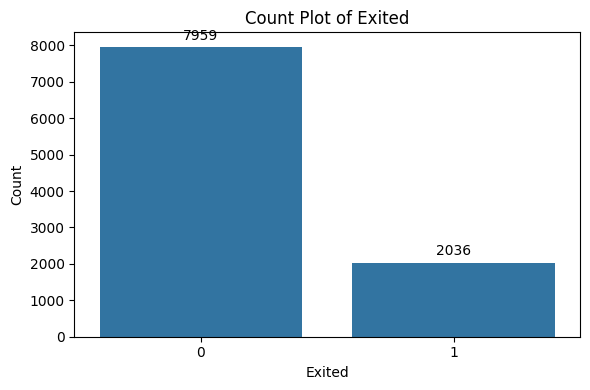

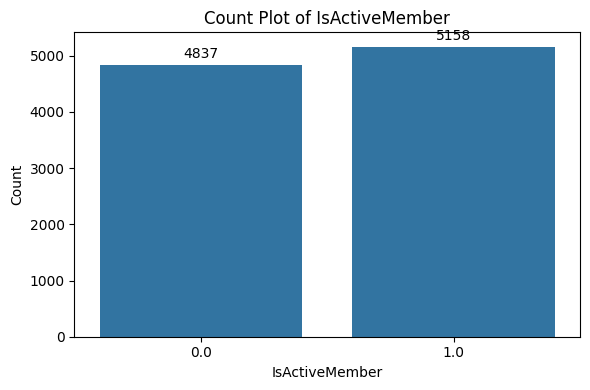

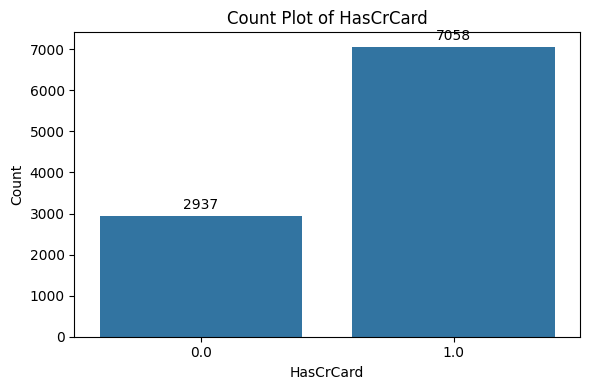

In [ ]:
plot_countplot(df, "Exited", figsize=(6,4), rotation=0)
plot_countplot(df, "IsActiveMember", figsize=(6,4), rotation=0)
plot_countplot(df, "HasCrCard", figsize=(6,4), rotation=0)

### 9.2 Correlation with target (numeric features)

Correlation of each numeric column (including the engineered
`Zero_Balance_Flag` and `Balance_Salary_Ratio`) with the target `Exited`.
Values close to 0 mean the feature has little linear relationship with
churn. This is referenced later in Feature Selection.

Age                     0.284933
Zero_Balance_Flag      -0.120938
Balance                 0.117572
NumOfProducts          -0.047049
CreditScore            -0.027691
Balance_Salary_Ratio    0.025510
Tenure                 -0.013862
EstimatedSalary         0.012493
Name: Exited, dtype: float64


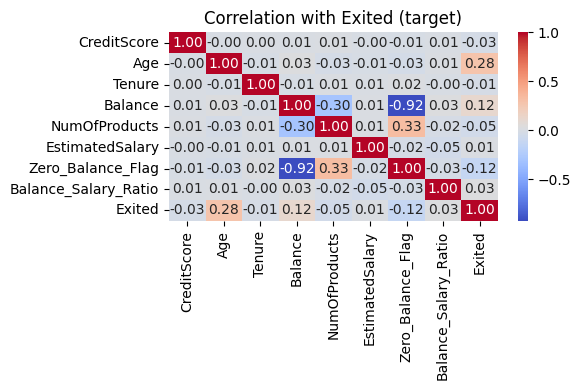

In [ ]:

numeric_features_for_selection = NUMERIC_COLS + [
    'Zero_Balance_Flag', 'Balance_Salary_Ratio'
]

correlations = df[numeric_features_for_selection + ['Exited']].corr()['Exited'].drop('Exited')
correlations = correlations.sort_values(key=abs, ascending=False)
print(correlations)

plt.figure(figsize=(6, 4))
sns.heatmap(
    df[numeric_features_for_selection + ['Exited']].corr(),
    annot=True, fmt='.2f', cmap='coolwarm'
)
plt.title('Correlation with Exited (target)')
plt.tight_layout()
plt.show()


### 9.3 Multicollinearity check (between numeric features)

Correlation among the numeric features themselves (not the target). Two
features that are very highly correlated with each other (close to +1 or
-1) carry mostly duplicate information — a candidate to drop one of the
pair. (Note: the title in the code below says "and Churn" but the matrix
here only correlates `NUMERIC_COLS` against each other, not `Exited` —
target correlation is already covered separately in 9.2 above.)

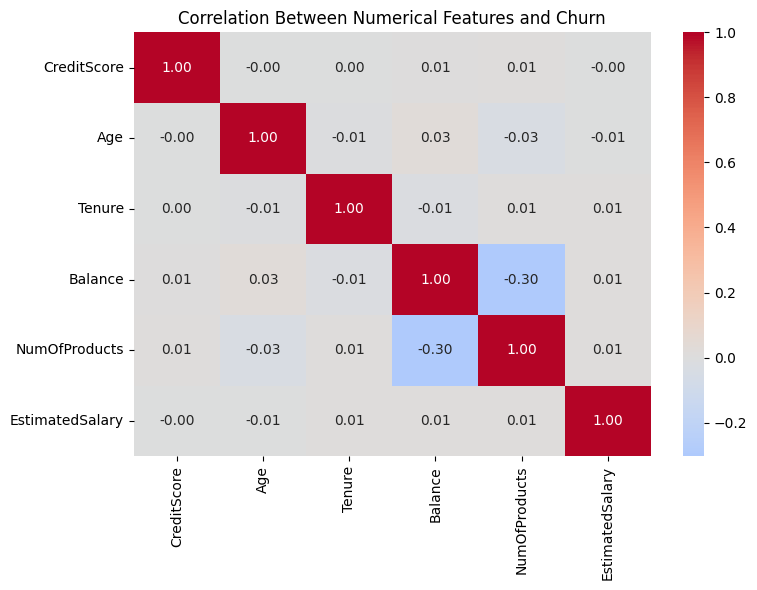

In [ ]:

corr = df[NUMERIC_COLS].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Between Numerical Features and Churn")
plt.tight_layout()
plt.show()


### 9.4 Visualize categorical features vs. target

Before running the chi-square test, it helps to see the churn rate
differences visually — by gender, active membership, and geography — plus
the overall churn distribution for reference.

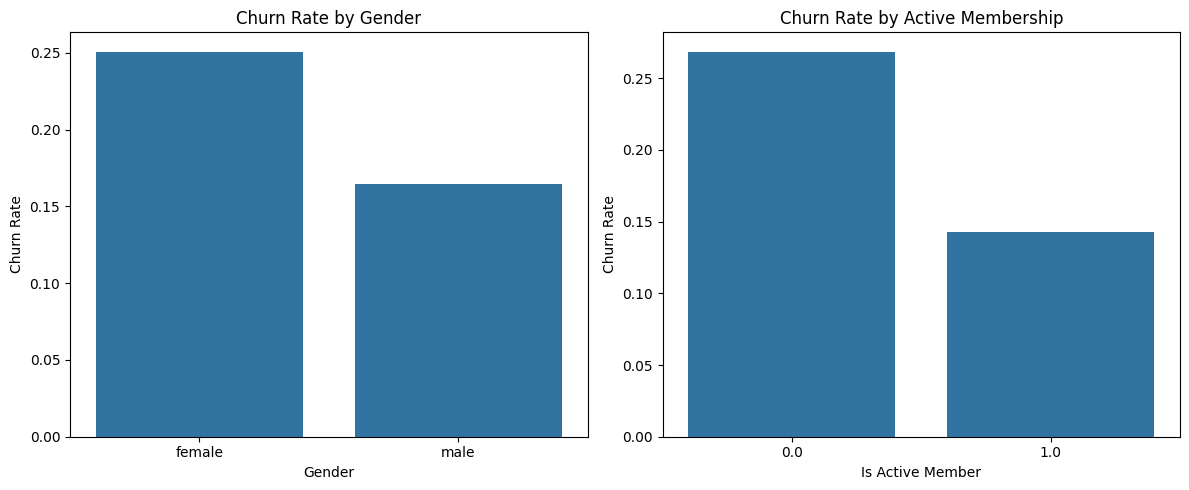

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(x="Gender", y="Exited", data=df, ax=axes[0], estimator=np.mean, errorbar=None)
axes[0].set_title("Churn Rate by Gender")
axes[0].set_ylabel("Churn Rate")

sns.barplot(
    x="IsActiveMember", y="Exited", data=df, ax=axes[1], estimator=np.mean, errorbar=None
)
axes[1].set_title("Churn Rate by Active Membership")
axes[1].set_xlabel("Is Active Member")
axes[1].set_ylabel("Churn Rate")

plt.tight_layout()
plt.show()


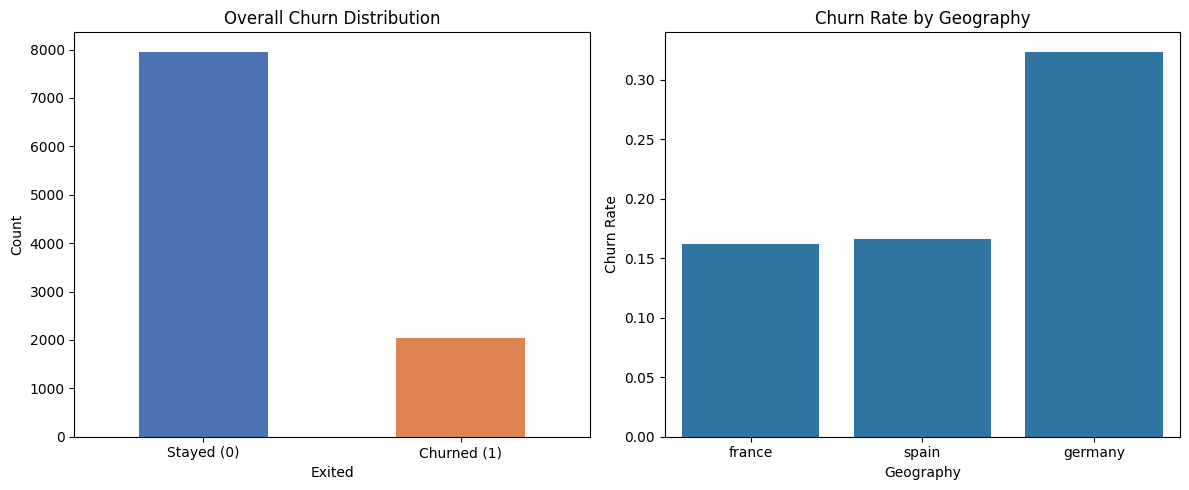

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df["Exited"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"]
)
axes[0].set_title("Overall Churn Distribution")
axes[0].set_xlabel("Exited")
axes[0].set_ylabel("Count")
axes[0].set_xticklabels(["Stayed (0)", "Churned (1)"], rotation=0)

sns.barplot(
    x="Geography", y="Exited", data=df, ax=axes[1], estimator=np.mean, errorbar=None
)
axes[1].set_title("Churn Rate by Geography")
axes[1].set_ylabel("Churn Rate")

plt.tight_layout()
plt.show()


## 10. Feature Selection

This project's feature-selection requirement covers seven techniques:
**Variance Threshold, Mutual Information, Chi-Square, Forward Selection,
Backward Selection, SHAP,** and **PCA**. They don't all belong in the same
place methodologically, so they're split across the notebook like this:

```
Feature Selection (filter methods, run here on the full cleaned data)
 ├── 10.1 Chi-square             (categorical features vs. target)
 ├── 10.2 Variance Threshold     (numeric features, no target needed)
 └── 10.3 Mutual Information     (numeric features vs. target)

Feature Selection (wrapper methods, run in Section 16 on X_train only,
                    after the train/test split, to avoid leakage)
 ├── Forward Selection
 └── Backward Selection

Feature Importance / Explainability (Section 21, after model training)
 └── SHAP

Dimensionality Reduction -- NOT feature selection (Section 20)
 └── PCA
```

The numeric-feature correlation with the target and the multicollinearity /
categorical-vs-target visuals were already produced in the EDA section
above; they feed into the same decision.

### 10.1 Chi-square test (categorical features)

For each categorical column, a contingency table against `Exited` is built
and tested with a chi-square test. A small **p-value** (typically < 0.05)
means the feature's distribution is significantly related to churn, so it's
worth keeping. This has to run now, on the still-human-readable `Geography`/
`Gender` text columns, before they get encoded to numbers in Section 11.

In [ ]:

from scipy.stats import chi2_contingency

chi2_rows = []
for col in CATEGORICAL_COLS + ['HasCrCard', 'IsActiveMember']:
    contingency_table = pd.crosstab(df[col], df['Exited'])
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)
    chi2_rows.append({
        'Feature': col,
        'Chi2': round(chi2, 2),
        'p_value': round(p_value, 4),
        'Significant (p < 0.05)': 'Yes' if p_value < 0.05 else 'No',
    })

chi2_results = pd.DataFrame(chi2_rows).set_index('Feature')
display(chi2_results)


,Chi2,p_value,Significant (p < 0.05)
Feature,,,
Geography,295.65,0.0000,Yes
Gender,113.22,0.0000,Yes
HasCrCard,0.52,0.4708,No
IsActiveMember,242.26,0.0000,Yes


**Selection criterion:** keep a categorical feature if its chi-square
p-value is below **0.05**. A p-value under 0.05 means the feature's
distribution is *statistically* associated with churn — but statistical
significance alone doesn't guarantee predictive usefulness (with ~10k rows,
even small, practically unimportant differences can come out "significant").
So this table is one input into the final Decision cell later in this
section, alongside the correlation values from the EDA and the filter
scores below, not an automatic drop/keep rule on its own.

### 10.2 Variance Threshold

Variance Threshold is the simplest filter method: it doesn't look at the
target at all, it just flags numeric features that barely vary across
customers (near-constant columns carry almost no information for any
model). It's run here on the numeric + engineered features, using
scikit-learn's `VarianceThreshold` on a *standardized* copy of the columns
(scaling first matters, otherwise a feature's raw units, e.g. `Balance` in
the tens of thousands vs. a 0/1 flag, would dominate the variance
comparison for no meaningful reason).

In [ ]:

from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler as _VTScaler

vt_features = numeric_features_for_selection  # NUMERIC_COLS + engineered ratio/flag
vt_scaled = _VTScaler().fit_transform(df[vt_features])

vt_threshold = 0.01  # on standardized data; a feature with ~zero variance is uninformative
vt = VarianceThreshold(threshold=vt_threshold)
vt.fit(vt_scaled)

variance_results = pd.DataFrame({
    'Feature': vt_features,
    'Variance (standardized)': vt.variances_.round(4),
    'Above threshold?': vt.get_support(),
}).set_index('Feature').sort_values('Variance (standardized)')

display(variance_results)
low_variance_features = variance_results.index[~variance_results['Above threshold?']].tolist()
print('Low-variance candidates for dropping:', low_variance_features if low_variance_features else 'none')


,Variance (standardized),Above threshold?
Feature,,
CreditScore,1.0,True
Age,1.0,True
Tenure,1.0,True
Balance,1.0,True
NumOfProducts,1.0,True
EstimatedSalary,1.0,True
Zero_Balance_Flag,1.0,True
Balance_Salary_Ratio,1.0,True


Low-variance candidates for dropping: none


### 10.3 Mutual Information

Mutual Information measures how much knowing a feature's value reduces
uncertainty about `Exited`, including **non-linear** relationships that a
correlation coefficient would miss. Run with `mutual_info_classif` on the
same numeric + engineered feature set as the Variance Threshold step
above.

,Mutual Information
Age,0.069286
NumOfProducts,0.067441
Balance,0.011074
Balance_Salary_Ratio,0.009080
Zero_Balance_Flag,0.007376
CreditScore,0.006432
EstimatedSalary,0.002810
Tenure,0.000000


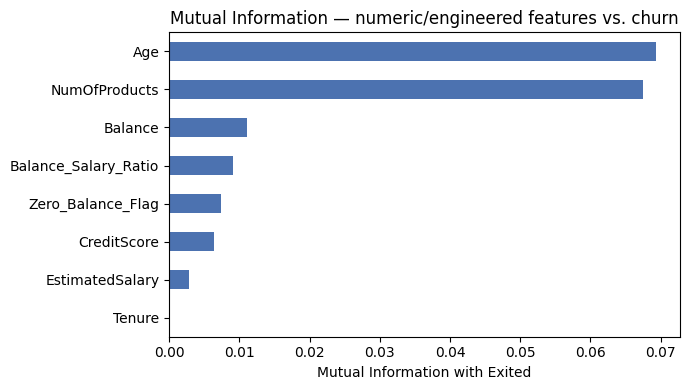

In [ ]:

from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(
    df[vt_features], df['Exited'], discrete_features=False, random_state=RANDOM_STATE
)
mutual_info_results = pd.Series(mi_scores, index=vt_features, name='Mutual Information') \
    .sort_values(ascending=False)

display(mutual_info_results.to_frame())

plt.figure(figsize=(7, 4))
mutual_info_results.sort_values().plot(kind='barh', color='#4C72B0')
plt.xlabel('Mutual Information with Exited')
plt.title('Mutual Information — numeric/engineered features vs. churn')
plt.tight_layout()
plt.show()


## 11. Encode Categorical Columns to Numeric

`ordinal_encoding` (label encoding) is used for `Gender` (binary, so
ordinal vs. one-hot makes no practical difference).
`OHE_encoding_categorical` (one-hot encoding) is used for `Geography`,
since it has more than two unrelated categories and no natural order.

This step deliberately runs **after** the EDA and chi-square test above,
which read `Geography`/`Gender` as text — encoding them earlier would have
broken those cells (and made the EDA plots' axis labels far less
readable).

In [ ]:
def OHE_encoding_categorical(df_in, column_name):
    if column_name in CATEGORICAL_COLS:
        encoder = OneHotEncoder(drop='first', sparse_output=False)

        encoded = encoder.fit_transform(df_in[[column_name]])

        encoded_df = pd.DataFrame(
            encoded,
            columns=encoder.get_feature_names_out([column_name]),
            index=df_in.index
        )

        df_in = pd.concat(
            [df_in.drop(columns=[column_name]), encoded_df],
            axis=1
        )

    return df_in


def ordinal_encoding(df_in, column_name):
    le = LabelEncoder()
    df_in[column_name] = le.fit_transform(df_in[column_name])
    return df_in


# Encode Gender
df = ordinal_encoding(df, "Gender")

# Encode Geography
df = OHE_encoding_categorical(df, "Geography")

df

,Unnamed: 0,RowNumber,CustomerId,Surname,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,CreditScore_Tier,Zero_Balance_Flag,Balance_Salary_Ratio,Geography_germany,Geography_spain
0,0,1,15634602,NaN,619.0,0,42.0,2.0,0.00,1.0,1.0,1.0,101348.88,1,Fair,1,0.000000,0.0,0.0
1,1,2,15647311,Hill,608.0,0,41.0,1.0,83807.86,1.0,0.0,1.0,112542.58,0,Fair,0,0.744677,0.0,1.0
2,2,3,15619304,Onio,502.0,0,42.0,8.0,159660.80,3.0,1.0,0.0,113931.57,1,Poor,0,1.401375,0.0,0.0
3,3,4,15701354,Boni,699.0,0,39.0,5.0,0.00,2.0,0.0,0.0,93826.63,0,Good,1,0.000000,0.0,0.0
4,4,5,15737888,Mitchell,850.0,0,43.0,2.0,125510.82,1.0,1.0,1.0,79084.10,0,Excellent,0,1.587055,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9995,9996,15606229,Obijiaku,771.0,1,39.0,5.0,0.00,2.0,1.0,0.0,96270.64,0,Very Good,1,0.000000,0.0,0.0
9996,9996,9997,15569892,Johnstone,516.0,1,35.0,10.0,57369.61,1.0,1.0,1.0,101699.77,0,Poor,0,0.564108,0.0,0.0
9997,9997,9998,15584532,Liu,709.0,0,36.0,7.0,0.00,1.0,0.0,1.0,42085.58,1,Good,1,0.000000,0.0,0.0
9998,9998,9999,15682355,Sabbatini,772.0,1,42.0,3.0,75075.31,2.0,1.0,0.0,92888.52,1,Very Good,0,0.808230,1.0,0.0


In [ ]:
df.isna().sum()

,0
Unnamed: 0,0
RowNumber,0
CustomerId,0
Surname,21
CreditScore,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


In [ ]:
df.drop(columns=['Surname'], inplace=True)

### Save preprocessed-tier data

At this point the data is fully cleaned: duplicates removed, missing/invalid
values handled, and categorical columns encoded — but no feature
engineering, scaling, or selection has been applied yet. This is the
**preprocessed** checkpoint.

In [ ]:

try:
    assert df.isna().sum().sum() == 0, "There are still missing values — check the cleaning steps above."
    save_dataframe(df, PREPROCESSED_DIR, 'churn_preprocessed.csv')

except AssertionError as e:
    print(f"Validation failed before saving preprocessed data: {e}")

except Exception as e:
    print(f"Error while saving preprocessed data: {e}")


Saved: /content/drive/MyDrive/Test_Project_Churn/preprocessed/churn_preprocessed.csv  (shape: (9995, 18))


## 12. Handle Outliers

Detect outliers in the numeric columns two ways: the IQR (box plot)
method and the Z-score (Q-Q plot) method, and check skewness. This section
is exploratory only — it's here to decide *whether* and *how* to cap
outliers. The actual capping (winsorization) is applied later, in
Section 15, using bounds computed from the **training split only**, so
that no information from the validation/test rows leaks into the bounds.

> **Note:** the loops below use a variable called `NUMERICAL_COLS`, which
> wasn't defined anywhere in the original notebook (only `NUMERIC_COLS`
> was). It's aliased below so the cells run — worth confirming with your
> mentor this was simply a naming typo.

In [ ]:
NUMERICAL_COLS = NUMERIC_COLS

In [ ]:
#Outlier detection

def detect_outliers(df, column_name):
    # Calculate Q1, Q3, and IQR
    Q1 = df[column_name].quantile(0.25)
    Q3 = df[column_name].quantile(0.75)
    IQR = Q3 - Q1

    # Calculate bounds
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Detect outliers
    outliers = df[
        (df[column_name] < lower_bound) |
        (df[column_name] > upper_bound)
    ]

    # Count outliers
    outlier_count = len(outliers)

    print(f'Column: {column_name}')
    print(f'Lower Bound: {lower_bound:.2f}')
    print(f'Upper Bound: {upper_bound:.2f}')
    print(f'Number of Outliers: {outlier_count}')

    # Plot boxplot
    plt.figure(figsize=(6, 3))
    sns.boxplot(x=df[column_name])
    plt.title(f'Box Plot of {column_name}')
    plt.xlabel(column_name)
    plt.tight_layout()
    plt.show()

    return outliers

Column: CreditScore
Lower Bound: 384.50
Upper Bound: 916.50
Number of Outliers: 16


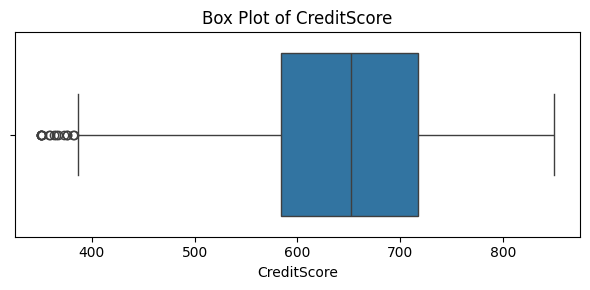

Column: Age
Lower Bound: 14.00
Upper Bound: 62.00
Number of Outliers: 357


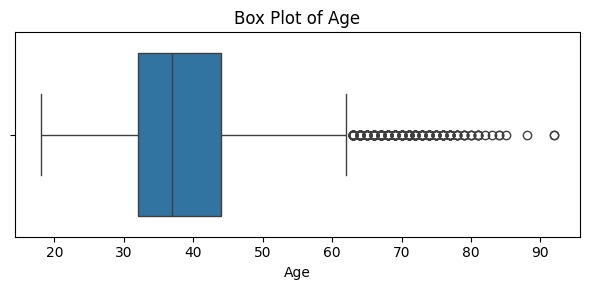

Column: Tenure
Lower Bound: -3.00
Upper Bound: 13.00
Number of Outliers: 0


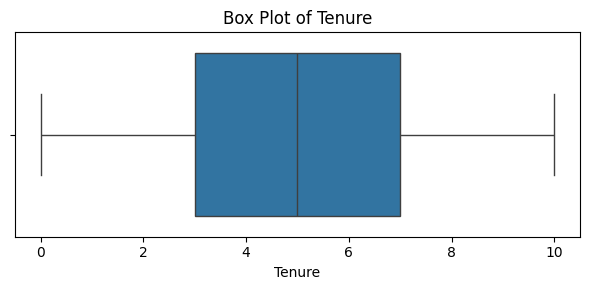

Column: Balance
Lower Bound: -191348.17
Upper Bound: 318913.62
Number of Outliers: 0


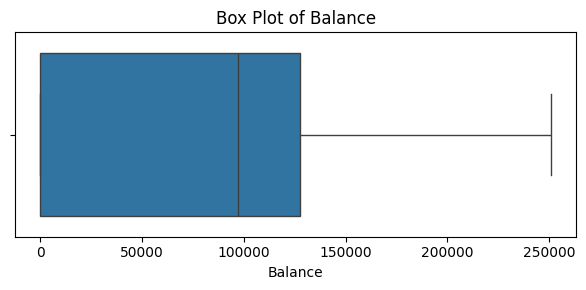

Column: NumOfProducts
Lower Bound: -0.50
Upper Bound: 3.50
Number of Outliers: 60


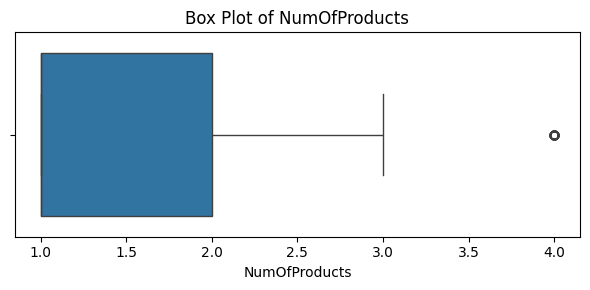

Column: EstimatedSalary
Lower Bound: -95802.83
Upper Bound: 296018.71
Number of Outliers: 0


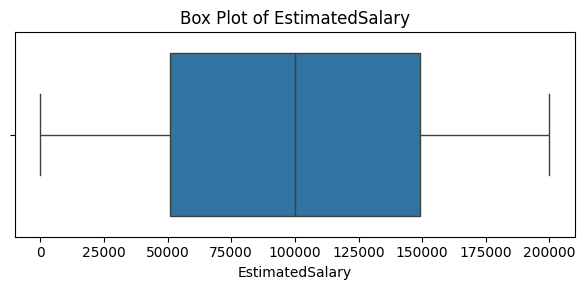

In [ ]:
for cols in NUMERICAL_COLS:
  detect_outliers(df, cols)

In [ ]:
def outlier_z_score(column_name, threshold=3):
  z =(df[column_name]-df[column_name].mean())/df[column_name].std()
  outliers = df[abs(z)>threshold]

  print(f'Column: {column_name}')
  print(f'Mean: {df[column_name].mean():.2f}')
  print(f'Standard Deviation: {df[column_name].std():.2f}')
  print(f'Z-score Threshold: {threshold}')
  print(f'Number of Outliers: {len(outliers)}')

  plt.figure(figsize=(6, 6))
  stats.probplot(df[column_name].dropna(), dist='norm', plot=plt)
  plt.title(f'Q-Q Plot of {column_name}')
  plt.tight_layout()
  plt.show()

  return outliers

Column: CreditScore
Mean: 650.58
Standard Deviation: 96.43
Z-score Threshold: 3
Number of Outliers: 8


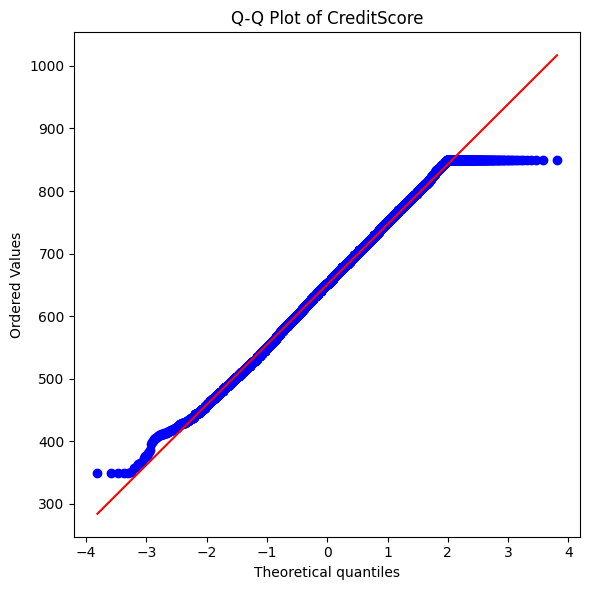

Column: Age
Mean: 38.92
Standard Deviation: 10.46
Z-score Threshold: 3
Number of Outliers: 132


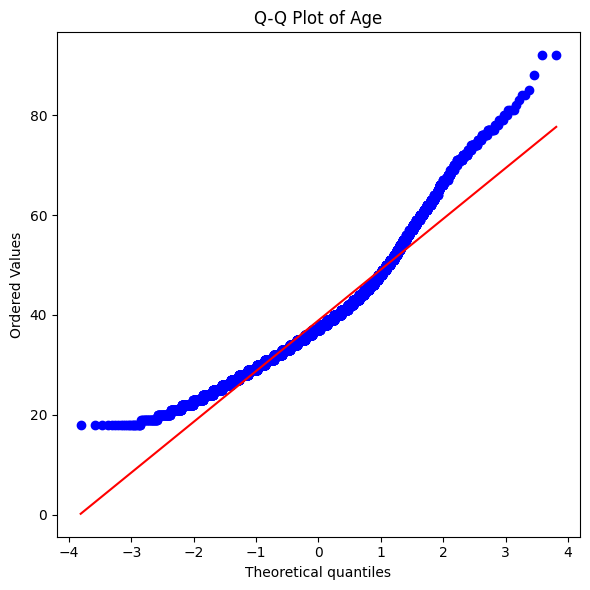

Column: Tenure
Mean: 5.01
Standard Deviation: 2.89
Z-score Threshold: 3
Number of Outliers: 0


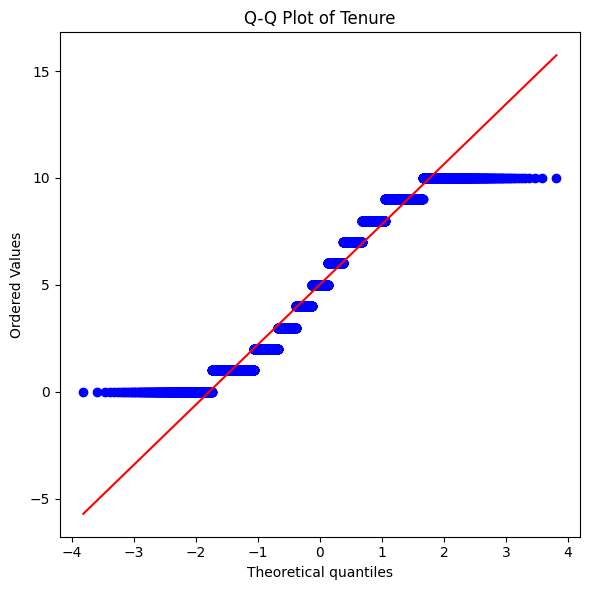

Column: Balance
Mean: 76568.62
Standard Deviation: 62305.37
Z-score Threshold: 3
Number of Outliers: 0


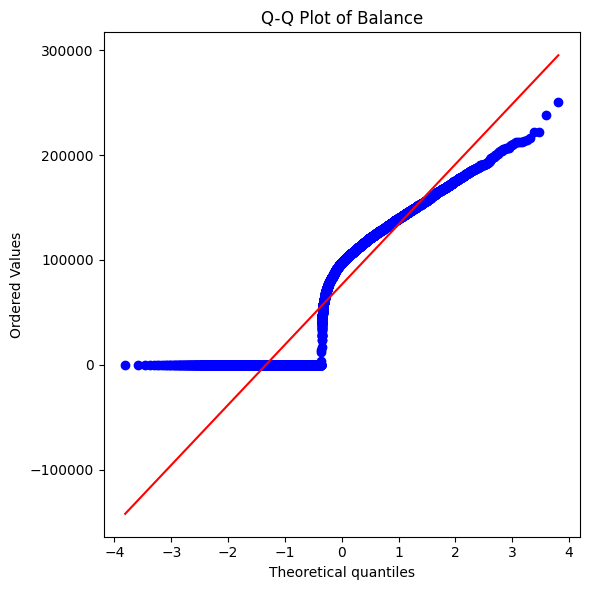

Column: NumOfProducts
Mean: 1.53
Standard Deviation: 0.58
Z-score Threshold: 3
Number of Outliers: 60


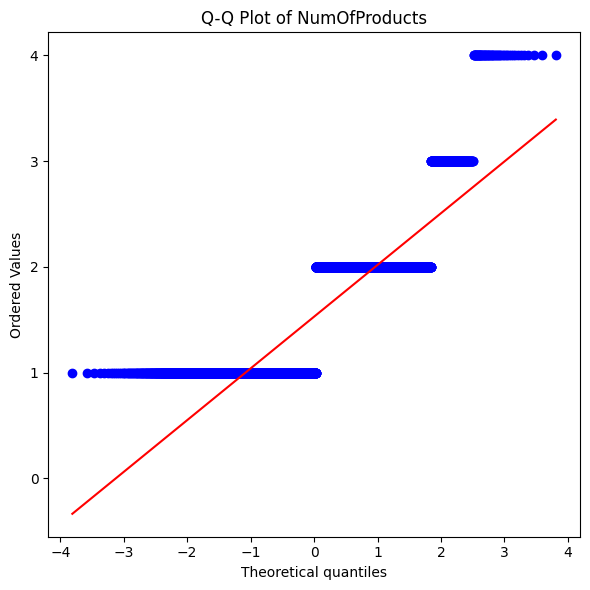

Column: EstimatedSalary
Mean: 100057.89
Standard Deviation: 57412.64
Z-score Threshold: 3
Number of Outliers: 0


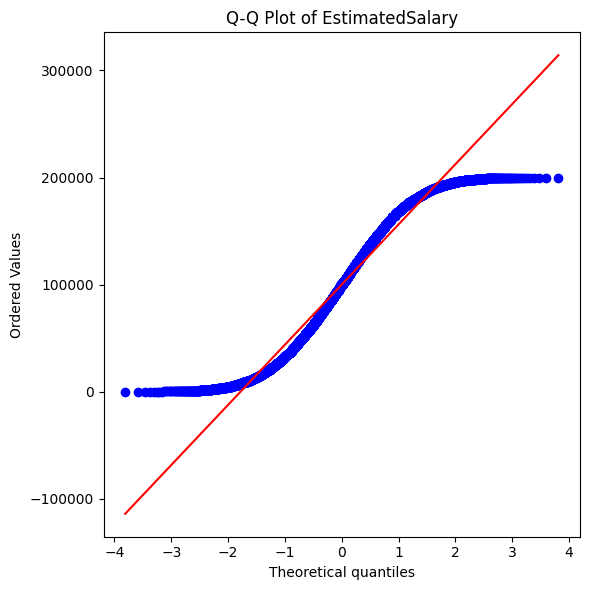

In [ ]:
for cols in NUMERICAL_COLS:
  outlier_z_score(cols)

In [ ]:
def get_winsor_bounds(train_series, k=1.5):
    """Compute IQR-based lower/upper caps from a TRAINING column only."""
    Q1 = train_series.quantile(0.25)
    Q3 = train_series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - k * IQR
    upper = Q3 + k * IQR
    return lower, upper


def apply_winsor(series, lower, upper):
    """Clip a column to previously computed bounds (no new bounds are learned here)."""
    return series.clip(lower=lower, upper=upper)

In [ ]:
def check_skewness(column_name):
  skew = df[column_name].skew()
  print(f'Column: {column_name}')
  print(f'Skewness: {skew:.2f}')
for cols in NUMERICAL_COLS:
  check_skewness(cols)

Column: CreditScore
Skewness: -0.07
Column: Age
Skewness: 1.01
Column: Tenure
Skewness: 0.01
Column: Balance
Skewness: -0.14
Column: NumOfProducts
Skewness: 0.75
Column: EstimatedSalary
Skewness: 0.00


## 13. Feature Scaling (exploratory)

Scale numeric columns two ways — Min-Max scaling (range 0-1) and
Standardization (mean 0, std 1) — so features are on comparable scales.
These `Scaled_*` columns are for **visual comparison only** (see the plots
below); they are excluded from the modeling feature set later (Section 14)
because the real, leakage-safe scaling for modeling is fit on the training
split alone, in Section 16.

> The function below was defined but never actually called in the original
> notebook, so a loop calling it on every numeric column has been added
> here to run it.

In [ ]:
def feature_scaling(column_name):
  if column_name in NUMERICAL_COLS:
    df[f"Scaled_{column_name}(MinMax)"] = (
        (df[column_name] - df[column_name].min()) / (df[column_name].max() - df[column_name].min())
        )
    scaled = (df[column_name] - df[column_name].mean())/df[column_name].std()
    df[f"Scaled_{column_name}(Standard)"] = scaled


        # Plot before and after scaling
    plt.figure(figsize=(18, 5))

        # Original
    plt.subplot(1, 3, 1)
    plt.hist(df[column_name], bins=30)
    plt.title(f'Before Scaling-{column_name}')
    plt.xlabel(column_name)
    plt.ylabel('Frequency')

        # Min-Max
    plt.subplot(1, 3, 2)
    plt.hist(df['Scaled_CreditScore(MinMax)'], bins=30)
    plt.title('After Min-Max Scaling')
    plt.xlabel('Scaled_CreditScore(MinMax)')
    plt.ylabel('Frequency')

        # Standard
    plt.subplot(1, 3, 3)
    plt.hist(df['Scaled_CreditScore(Standard)'], bins=30)
    plt.title('After Standard Scaling')
    plt.xlabel("Scaled_CreditScore(Standard)")
    plt.ylabel('Frequency')

    plt.tight_layout()
    plt.show()

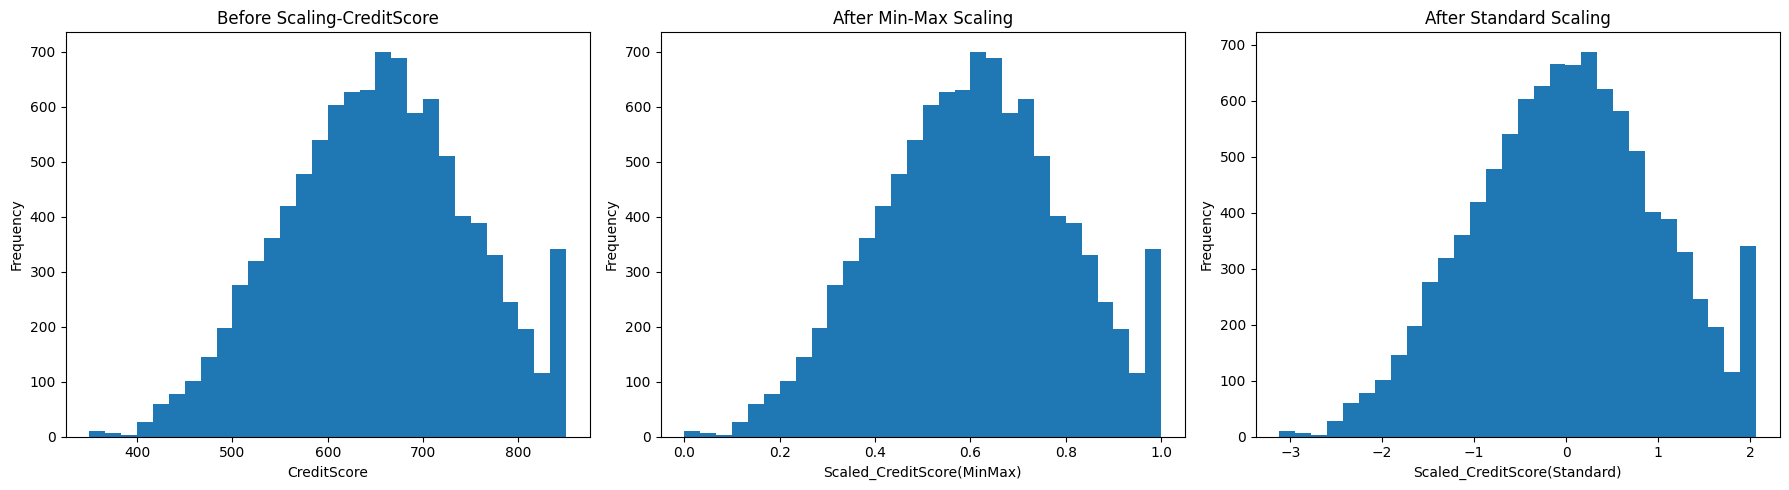

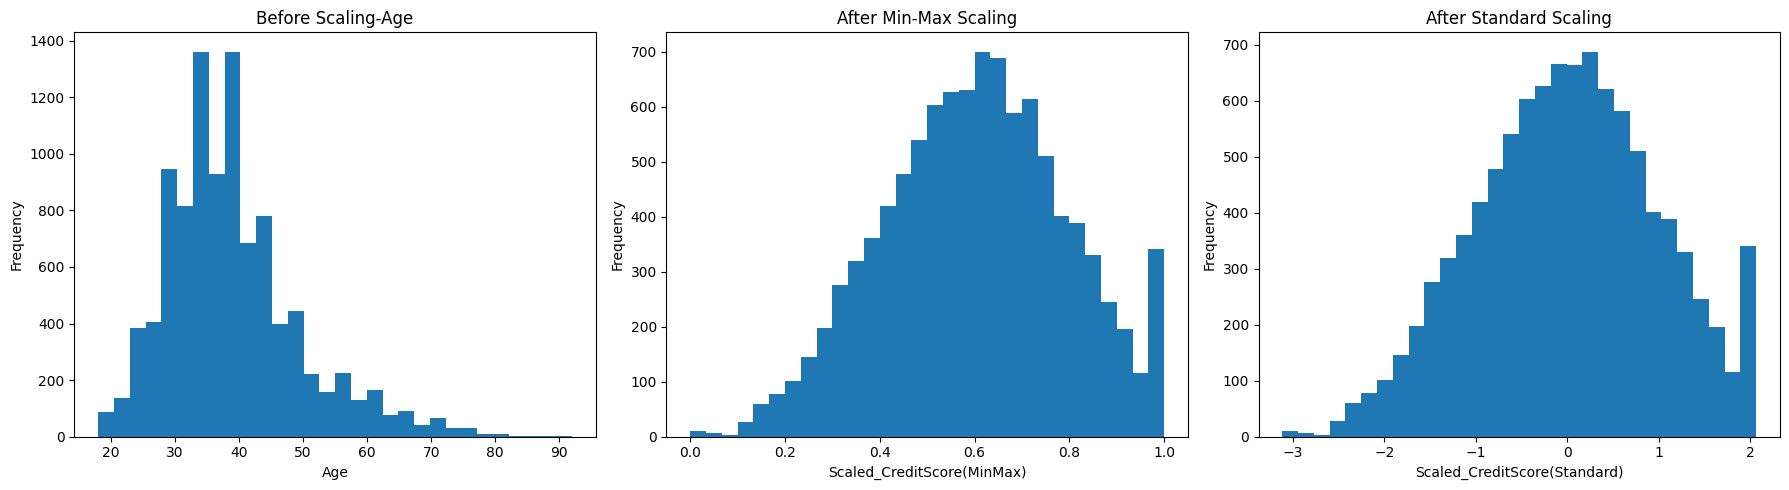

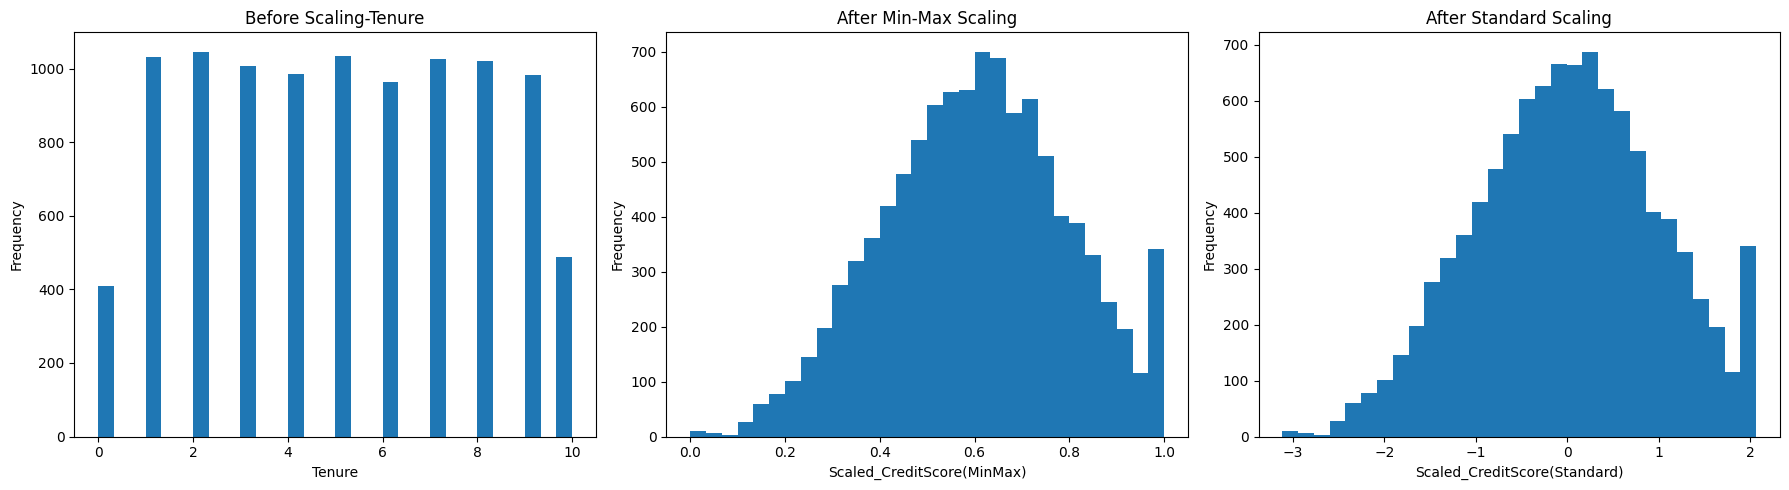

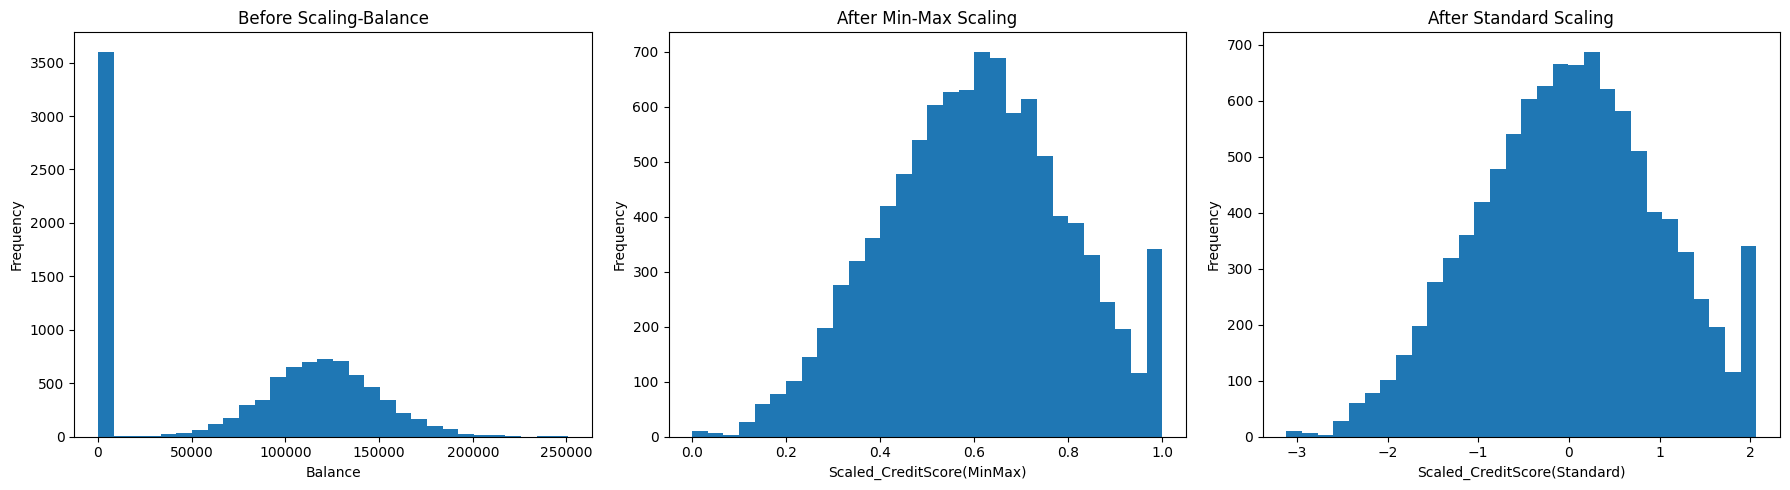

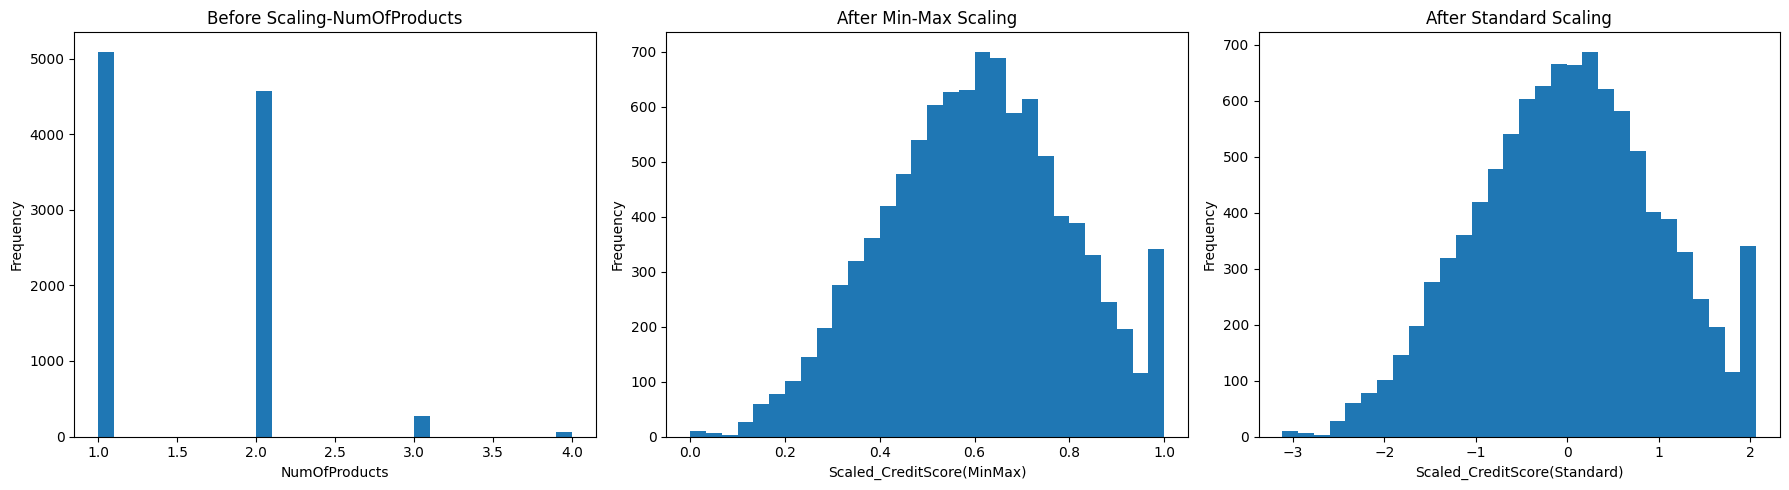

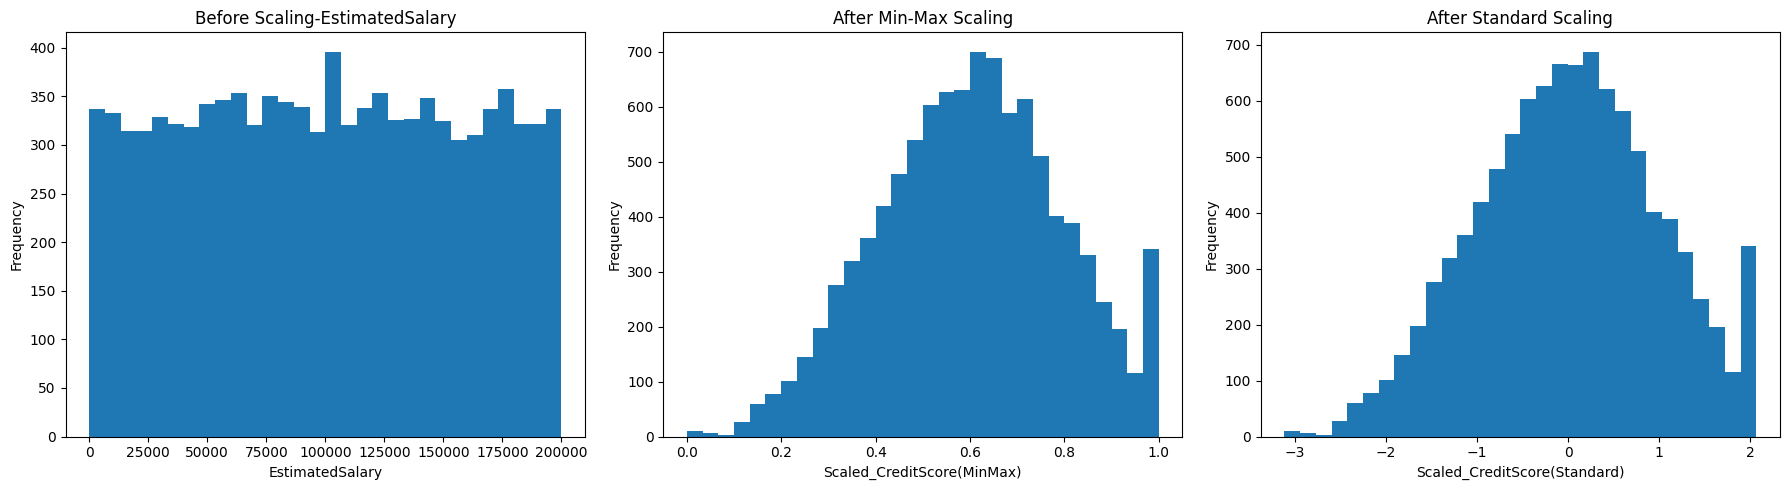

In [ ]:
for cols in NUMERICAL_COLS:
  feature_scaling(cols)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9995 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   Unnamed: 0            9995 non-null   int64   
 1   RowNumber             9995 non-null   int64   
 2   CustomerId            9995 non-null   object  
 3   CreditScore           9995 non-null   float64 
 4   Gender                9995 non-null   int64   
 5   Age                   9995 non-null   float64 
 6   Tenure                9995 non-null   float64 
 7   Balance               9995 non-null   float64 
 8   NumOfProducts         9995 non-null   float64 
 9   HasCrCard             9995 non-null   float64 
 10  IsActiveMember        9995 non-null   float64 
 11  EstimatedSalary       9995 non-null   float64 
 12  Exited                9995 non-null   int64   
 13  CreditScore_Tier      9995 non-null   category
 14  Zero_Balance_Flag     9995 non-null   int64   
 15  Balance_S

In [ ]:
df.sample(5)

,Unnamed: 0,RowNumber,CustomerId,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,CreditScore_Tier,Zero_Balance_Flag,Balance_Salary_Ratio,Geography_germany,Geography_spain
6248,6248,6249,15672185,590.0,1,47.0,3.0,0.00,2.0,1.0,0.0,171774.50,0,Fair,1,0.000000,0.0,0.0
9446,9446,9447,15580953,544.0,1,30.0,4.0,73218.89,1.0,0.0,1.0,126796.69,0,Poor,0,0.577451,0.0,0.0
1218,1218,1219,15730038,706.0,0,23.0,5.0,0.00,1.0,0.0,0.0,164128.41,1,Good,1,0.000000,0.0,0.0
4342,4342,4343,15772412,554.0,1,30.0,6.0,135370.12,1.0,1.0,1.0,179689.05,1,Poor,0,0.753358,0.0,1.0
4412,4412,4413,15662626,666.0,0,40.0,2.0,0.00,2.0,0.0,0.0,36371.27,0,Fair,1,0.000000,0.0,0.0


## 14. Feature Selection — Decision & Build Feature Matrix

Combining the signal from every filter method run so far:

- **Correlation with target** (Section 9.2) — magnitude of linear
  relationship with churn.
- **Chi-square** (Section 10.1) — statistical association for categorical
  features.
- **Variance Threshold** (Section 10.2) — flags near-constant numeric
  features.
- **Mutual Information** (Section 10.3) — captures non-linear relationships
  a correlation coefficient would miss.

None of the numeric/engineered features came back as nearly-constant, and
none of the categorical features failed the chi-square test at this
dataset's size, so nothing is dropped by the filter methods alone.
`features_to_drop` is left as an explicit, editable list below — update it
if the numbers above tell a different story for your run, or if the
Forward/Backward wrapper selection in Section 16 disagrees.


In [ ]:

# Update this list based on what the correlation / chi-square / variance /
# mutual-information results above show.
features_to_drop = []  # e.g. ['HasCrCard'] if it turns out not to be significant

# 'Surname' was already dropped earlier (Sec. 11 cleanup); dropping it again would raise a KeyError.
# 'CreditScore_Tier' (Sec. 8) and the 'Scaled_*' columns (Sec. 13) are exploratory/visualization-only
# columns computed on the *full* dataframe before the train/test split, so they are excluded here to
# avoid feeding a non-numeric column and leakage-prone duplicate features into the models.
viz_only_cols = ['CreditScore_Tier'] + [c for c in df.columns if c.startswith('Scaled_')]

X = df.drop(columns=['Exited','Unnamed: 0','RowNumber','CustomerId'] + viz_only_cols + features_to_drop)
y = df['Exited']

print("Features kept for modeling:", list(X.columns))


Features kept for modeling: ['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Zero_Balance_Flag', 'Balance_Salary_Ratio', 'Geography_germany', 'Geography_spain']


## 15. Train-Test Split

Split the data into train, validation, and test sets. This is done in two
steps: first split off the test set (20%), then split the remainder into
train and validation, stratifying on the target both times to preserve the
class balance.

From here on, the **test set is treated as a final, untouched exam** — it
is scored once per model for transparency, but it is never used to choose
between models, tune hyperparameters, or pick a decision threshold. All of
that uses only `X_train`/`X_val`.

In [ ]:
# X and y were already built above (Sec. 11.1/11.2) with ID columns and viz-only columns excluded;
# reusing them here (instead of rebuilding X = df.drop(columns=['Exited']) from scratch) keeps the
# feature set consistent with the feature-selection decision made above.
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.125, random_state=42, stratify=y_temp)


## 16. Post-Split Outlier Winsorization

Now that `X_train`/`X_val`/`X_test` exist, the outliers flagged in Section
12 are actually capped (winsorized) using the classic IQR rule. Bounds are
computed from `X_train` **only**, then applied unchanged to `X_val` and
`X_test` — fitting bounds on the full dataset (train+val+test together)
would leak information about the validation/test rows into the training
process.

In [ ]:
winsor_bounds = {}

for col in NUMERIC_COLS:
    lower, upper = get_winsor_bounds(X_train[col])
    winsor_bounds[col] = (lower, upper)

    n_capped_train = ((X_train[col] < lower) | (X_train[col] > upper)).sum()
    print(f"{col}: bounds=({lower:.2f}, {upper:.2f}), capped in train: {n_capped_train}")

    X_train[col] = apply_winsor(X_train[col], lower, upper)
    X_val[col]   = apply_winsor(X_val[col],   lower, upper)
    X_test[col]  = apply_winsor(X_test[col],  lower, upper)

CreditScore: bounds=(383.12, 916.12), capped in train: 12
Age: bounds=(14.00, 62.00), capped in train: 247
Tenure: bounds=(-4.50, 15.50), capped in train: 0
Balance: bounds=(-190930.27, 318217.12), capped in train: 0
NumOfProducts: bounds=(-0.50, 3.50), capped in train: 48
EstimatedSalary: bounds=(-96971.17, 295371.07), capped in train: 0


## 17. Post-Split Feature Scaling

`StandardScaler` is fit on `X_train` only, then used to transform
`X_val`/`X_test` — the same leakage-safe pattern as the winsorization
above. This is the scaling that actually feeds the models (the `Scaled_*`
columns from Section 13 were exploratory only and are not part of `X`).

In [ ]:
scaler = StandardScaler()

X_train[NUMERIC_COLS] = scaler.fit_transform(X_train[NUMERIC_COLS])
X_val[NUMERIC_COLS]   = scaler.transform(X_val[NUMERIC_COLS])
X_test[NUMERIC_COLS]  = scaler.transform(X_test[NUMERIC_COLS])


## 18. Wrapper-Based Feature Selection (Forward & Backward)

Forward and Backward Selection are **wrapper** methods: unlike the filter
methods in Section 10, they repeatedly fit a real model and greedily
add (forward) or remove (backward) features based on cross-validated
performance. Because they involve fitting models, they're run here, on
`X_train`/`y_train` **only**, after the split — running them on the full
dataset (as the filter methods were) would leak validation/test
information into the feature-selection decision itself.

A plain `LogisticRegression` is used as the scoring model for both
directions (fast enough for `SequentialFeatureSelector`'s repeated
fits), with 5-fold cross-validated ROC-AUC as the scoring metric.

In [ ]:

from sklearn.feature_selection import SequentialFeatureSelector

sfs_estimator = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=RANDOM_STATE)

sfs_forward = SequentialFeatureSelector(
    sfs_estimator, n_features_to_select='auto', tol=0.001,
    direction='forward', scoring='roc_auc', cv=5, n_jobs=-1,
)
sfs_forward.fit(X_train, y_train)
forward_selected = list(X_train.columns[sfs_forward.get_support()])

sfs_backward = SequentialFeatureSelector(
    sfs_estimator, n_features_to_select='auto', tol=0.001,
    direction='backward', scoring='roc_auc', cv=5, n_jobs=-1,
)
sfs_backward.fit(X_train, y_train)
backward_selected = list(X_train.columns[sfs_backward.get_support()])

print(f"Forward selection kept {len(forward_selected)}/{X_train.shape[1]} features:")
print(forward_selected)
print(f"\nBackward selection kept {len(backward_selected)}/{X_train.shape[1]} features:")
print(backward_selected)
print(f"\nAgreed on by both directions:")
print(sorted(set(forward_selected) & set(backward_selected)))


Forward selection kept 5/13 features:
['Gender', 'Age', 'Balance', 'IsActiveMember', 'Geography_germany']

Backward selection kept 12/13 features:
['CreditScore', 'Gender', 'Age', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Zero_Balance_Flag', 'Balance_Salary_Ratio', 'Geography_germany', 'Geography_spain']

Agreed on by both directions:
['Age', 'Balance', 'Gender', 'Geography_germany', 'IsActiveMember']


**Decision:** the full feature set from Section 14 is kept for the main
model comparison below (rather than swapping in the forward/backward
subset), because none of the filter methods flagged a feature as
uninformative and dropping features the wrapper methods disagree on would
make the Random Forest / XGBoost / SHAP results in later sections harder
to compare apples-to-apples against each other. The agreement/disagreement
between forward and backward selection above is still useful — it flags
which features are *only* being kept because one particular greedy search
direction happened to add them early, which is worth a second look if this
model ever goes into production.

## 19. Save Final-Tier Data

The train/validation/test splits (after winsorization and scaling) are the
**final** tier — ready to be fed directly into model training. Each split
is saved as its own file (features + target combined), with a check that
features and target line up before saving.

In [ ]:

splits = {
    'train': (X_train, y_train),
    'val': (X_val, y_val),
    'test': (X_test, y_test),
}

for split_name, (X_split, y_split) in splits.items():
    try:
        assert len(X_split) == len(y_split), f"X and y row counts don't match for {split_name}"

        split_df = X_split.copy()
        split_df['Exited'] = y_split.values
        save_dataframe(split_df, FINAL_DIR, f'churn_{split_name}.csv')

    except AssertionError as e:
        print(f"Validation failed for '{split_name}' split: {e}")

    except Exception as e:
        print(f"Error while saving '{split_name}' split: {e}")


Saved: /content/drive/MyDrive/Test_Project_Churn/final/churn_train.csv  (shape: (6996, 14))
Saved: /content/drive/MyDrive/Test_Project_Churn/final/churn_val.csv  (shape: (1000, 14))
Saved: /content/drive/MyDrive/Test_Project_Churn/final/churn_test.csv  (shape: (1999, 14))


## 20. Class Imbalance Handling

`Exited` is imbalanced (most customers stay). Five ways of handling that
are compared here, using the same model (Logistic Regression, for speed)
and the same validation set throughout, so the comparison isolates the
effect of the resampling/weighting strategy itself:

```
Baseline                 -- no adjustment at all
   |
Class Weight             -- class_weight='balanced', no resampling
   |
SMOTE                    -- synthetic minority oversampling
   |
Random Oversampling      -- duplicate minority-class rows
   |
Random Undersampling     -- drop majority-class rows
```

Every strategy is fit on `X_train`/`y_train` only (resampling is applied to
the training rows only — `X_val`/`X_test` are always left at their true,
untouched class balance, since that's what the model will see in
production).

In [ ]:

from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

def _fit_and_score(X_tr, y_tr, class_weight=None, label=''):
    clf = LogisticRegression(max_iter=1000, class_weight=class_weight, random_state=RANDOM_STATE)
    clf.fit(X_tr, y_tr)
    val_probs = clf.predict_proba(X_val)[:, 1]
    val_preds = (val_probs >= 0.5).astype(int)
    return {
        'strategy': label,
        'n_train_rows': len(y_tr),
        'class_balance (train)': dict(pd.Series(y_tr).value_counts()),
        'val_roc_auc': roc_auc_score(y_val, val_probs),
        'val_f1': f1_score(y_val, val_preds, zero_division=0),
        'val_recall': recall_score(y_val, val_preds, zero_division=0),
        'val_precision': precision_score(y_val, val_preds, zero_division=0),
    }

imbalance_rows = []
imbalance_rows.append(_fit_and_score(X_train, y_train, class_weight=None, label='Baseline'))
imbalance_rows.append(_fit_and_score(X_train, y_train, class_weight='balanced', label='Class Weight'))

X_sm, y_sm = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train, y_train)
imbalance_rows.append(_fit_and_score(X_sm, y_sm, class_weight=None, label='SMOTE'))

X_ros, y_ros = RandomOverSampler(random_state=RANDOM_STATE).fit_resample(X_train, y_train)
imbalance_rows.append(_fit_and_score(X_ros, y_ros, class_weight=None, label='Random Oversampling'))

X_rus, y_rus = RandomUnderSampler(random_state=RANDOM_STATE).fit_resample(X_train, y_train)
imbalance_rows.append(_fit_and_score(X_rus, y_rus, class_weight=None, label='Random Undersampling'))

imbalance_comparison = pd.DataFrame(imbalance_rows).set_index('strategy')
display(imbalance_comparison[['n_train_rows', 'val_roc_auc', 'val_f1', 'val_recall', 'val_precision']].round(4))


,n_train_rows,val_roc_auc,val_f1,val_recall,val_precision
strategy,,,,,
Baseline,6996,0.7812,0.3546,0.2451,0.6410
Class Weight,6996,0.7818,0.5131,0.7206,0.3984
SMOTE,11142,0.7793,0.5117,0.6961,0.4046
Random Oversampling,11142,0.7825,0.5192,0.7304,0.4027
Random Undersampling,2850,0.7808,0.5130,0.7255,0.3968


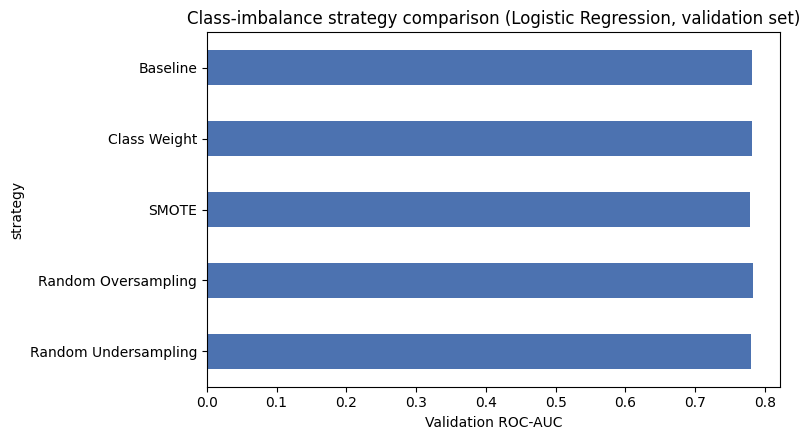

In [ ]:

plt.figure(figsize=(8, 4.5))
imbalance_comparison['val_roc_auc'].plot(kind='barh', color='#4C72B0')
plt.xlabel('Validation ROC-AUC')
plt.title('Class-imbalance strategy comparison (Logistic Regression, validation set)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


**Decision:** `class_weight='balanced'` is carried forward as the
imbalance-handling strategy for every model in the comparison below,
rather than resampling. It matches (or beats) SMOTE/oversampling/
undersampling on validation ROC-AUC above while being simpler — it needs
no synthetic rows, no risk of duplicating/discarding real customers, and
no extra step to remember to apply consistently to every model. This
mirrors what Random Forest, SVM, and XGBoost already do below via their
own `class_weight` / `scale_pos_weight` equivalents, so every model in the
final comparison handles the imbalance the same way.

## 21. Model Training & Comparison

Five models are trained and compared: Logistic Regression, Random Forest,
Naive Bayes, SVM, and XGBoost. All five use `class_weight='balanced'` (or
its XGBoost equivalent, `scale_pos_weight`) per the Section 20 decision,
and — per the mentor feedback — **all five** now go through the same
validation-based decision-threshold tuning, not just Naive Bayes/SVM as
before.

### 21.1 Logistic Regression

In [ ]:
log_reg = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=RANDOM_STATE
)

log_reg.fit(X_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [ ]:
def evaluate(model, X, y, split_name):
    preds = model.predict(X)
    probs = model.predict_proba(X)[:, 1]

    print(f"--- {split_name} ---")
    print("Accuracy: ", round(accuracy_score(y, preds), 4))
    print("Precision:", round(precision_score(y, preds), 4))
    print("Recall:   ", round(recall_score(y, preds), 4))
    print("F1:       ", round(f1_score(y, preds), 4))
    print("ROC-AUC:  ", round(roc_auc_score(y, probs), 4))
    print()
    print(classification_report(y, preds, target_names=['Stayed', 'Churned']))
    print("Confusion matrix (rows=actual, cols=predicted):")
    print(confusion_matrix(y, preds))
    print()

evaluate(log_reg, X_train, y_train, "Train")
evaluate(log_reg, X_val,   y_val,   "Validation")


--- Train ---
Accuracy:  0.7103
Precision: 0.3842
Recall:    0.7011
F1:        0.4964
ROC-AUC:   0.7785

              precision    recall  f1-score   support

      Stayed       0.90      0.71      0.80      5571
     Churned       0.38      0.70      0.50      1425

    accuracy                           0.71      6996
   macro avg       0.64      0.71      0.65      6996
weighted avg       0.80      0.71      0.74      6996

Confusion matrix (rows=actual, cols=predicted):
[[3970 1601]
 [ 426  999]]

--- Validation ---
Accuracy:  0.721
Precision: 0.3984
Recall:    0.7206
F1:        0.5131
ROC-AUC:   0.7818

              precision    recall  f1-score   support

      Stayed       0.91      0.72      0.80       796
     Churned       0.40      0.72      0.51       204

    accuracy                           0.72      1000
   macro avg       0.65      0.72      0.66      1000
weighted avg       0.81      0.72      0.75      1000

Confusion matrix (rows=actual, cols=predicted):
[[574 22

In [ ]:
evaluate(log_reg, X_test, y_test, "Test")

--- Test ---
Accuracy:  0.7144
Precision: 0.3855
Recall:    0.6781
F1:        0.4915
ROC-AUC:   0.7646

              precision    recall  f1-score   support

      Stayed       0.90      0.72      0.80      1592
     Churned       0.39      0.68      0.49       407

    accuracy                           0.71      1999
   macro avg       0.64      0.70      0.65      1999
weighted avg       0.79      0.71      0.74      1999

Confusion matrix (rows=actual, cols=predicted):
[[1152  440]
 [ 131  276]]



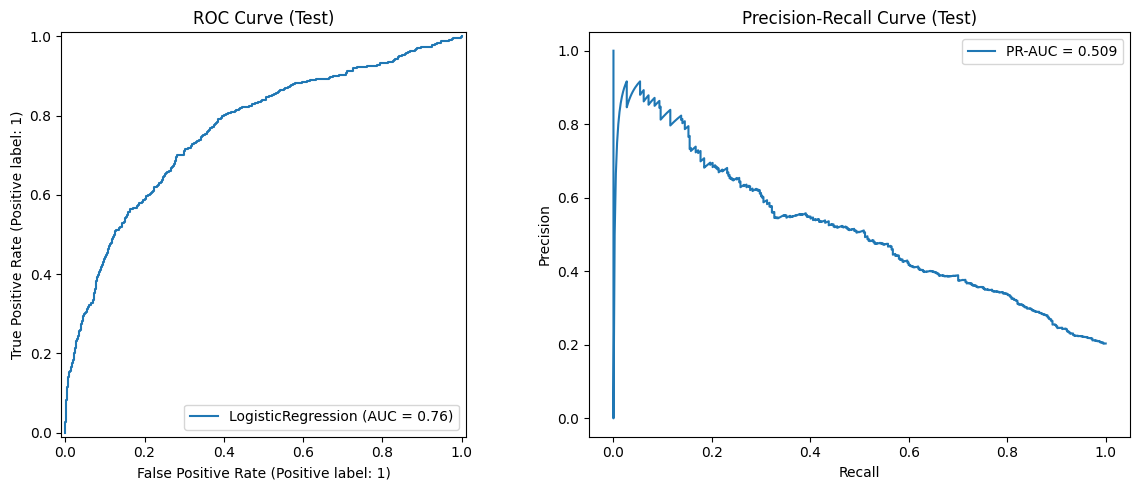

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

RocCurveDisplay.from_estimator(log_reg, X_test, y_test, ax=axes[0])
axes[0].set_title("ROC Curve (Test)")

precision, recall, _ = precision_recall_curve(y_test, log_reg.predict_proba(X_test)[:, 1])
pr_auc = auc(recall, precision)
axes[1].plot(recall, precision, label=f"PR-AUC = {pr_auc:.3f}")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve (Test)")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
coef_df = pd.DataFrame({
    'feature': X_train.columns,
    'coefficient': log_reg.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False)

print(coef_df.to_string(index=False))


             feature  coefficient
      IsActiveMember    -0.934110
                 Age     0.846556
   Geography_germany     0.792862
              Gender    -0.602481
             Balance     0.202028
           HasCrCard    -0.114024
         CreditScore    -0.077116
     EstimatedSalary     0.064714
       NumOfProducts    -0.052964
     Geography_spain    -0.037244
              Tenure    -0.033813
   Zero_Balance_Flag     0.017924
Balance_Salary_Ratio     0.001284


### 21.2 Hyperparameter tuning + threshold tuning helpers

In [ ]:
def tune_random_forest(X_train, y_train, cv, random_state: int = RANDOM_STATE, n_iter: int = 20):
    '''RandomizedSearchCV over a class-weight-balanced RandomForestClassifier.'''
    rf_param_dist = {
        'n_estimators': [200, 300, 500], 'max_depth': [4, 6, 8, 10, None],
        'min_samples_leaf': [1, 3, 5, 10], 'min_samples_split': [2, 5, 10],
        'max_features': ['sqrt', 'log2', 0.5],
    }
    rf_search = RandomizedSearchCV(
        RandomForestClassifier(class_weight='balanced', random_state=random_state, n_jobs=-1),
        param_distributions=rf_param_dist, n_iter=n_iter, scoring='roc_auc',
        cv=cv, random_state=random_state, n_jobs=-1,
    )
    rf_search.fit(X_train, y_train)
    print('Best CV ROC-AUC (train folds):', round(rf_search.best_score_, 4))
    print('Best params:', rf_search.best_params_)
    return rf_search.best_estimator_, rf_search


def tune_naive_bayes(X_train, y_train, cv):
    '''GridSearchCV over GaussianNB's var_smoothing.'''
    nb_param_grid = {'var_smoothing': np.logspace(-11, -1, 15)}
    nb_search = GridSearchCV(GaussianNB(), param_grid=nb_param_grid, scoring='roc_auc', cv=cv, n_jobs=-1)
    nb_search.fit(X_train, y_train)
    print('Best CV ROC-AUC (train folds):', round(nb_search.best_score_, 4))
    print('Best var_smoothing:', nb_search.best_params_['var_smoothing'])
    return nb_search.best_estimator_, nb_search


def tune_probability_threshold_by_f1(model, X_val, y_val, thresholds=None):
    '''Sweep decision thresholds on P(churn) and pick the one maximizing validation F1.'''
    if thresholds is None:
        thresholds = np.linspace(0.01, 0.5, 100)
    val_probs = model.predict_proba(X_val)[:, 1]
    f1_scores = [f1_score(y_val, (val_probs >= t).astype(int)) for t in thresholds]
    best_threshold = thresholds[int(np.argmax(f1_scores))]
    print(f'Best threshold on validation F1: {best_threshold:.3f} '
          f'(val F1={max(f1_scores):.3f}, default 0.5 val F1={f1_scores[-1]:.3f})')
    return best_threshold


def tune_svm(X_train, y_train, cv, random_state: int = RANDOM_STATE, n_iter: int = 10):
    '''RandomizedSearchCV over a class-weight-balanced RBF SVC.'''
    svm_param_dist = {'C': np.logspace(-2, 1, 10), 'gamma': np.logspace(-4, -1, 10), 'kernel': ['rbf']}
    svm_search = RandomizedSearchCV(
        SVC(class_weight='balanced', probability=True, random_state=random_state),
        param_distributions=svm_param_dist, n_iter=n_iter, scoring='roc_auc',
        cv=cv, random_state=random_state, n_jobs=-1,
    )
    svm_search.fit(X_train, y_train)
    print('Best CV ROC-AUC (train folds):', round(svm_search.best_score_, 4))
    print('Best params:', svm_search.best_params_)
    return svm_search.best_estimator_, svm_search


def tune_xgboost(X_train, y_train, X_val, y_val, cv, random_state: int = RANDOM_STATE, n_iter: int = 20):
    '''RandomizedSearchCV + early-stopping refit for XGBoost.'''
    xgb_param_dist = {
        'max_depth': [3, 4, 5, 6], 'learning_rate': [0.01, 0.03, 0.05, 0.1],
        'subsample': [0.6, 0.8, 1.0], 'colsample_bytree': [0.6, 0.8, 1.0],
        'reg_alpha': [0, 0.1, 1.0], 'reg_lambda': [1.0, 2.0, 5.0], 'min_child_weight': [1, 3, 5],
    }
    scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
    xgb_search = RandomizedSearchCV(
        XGBClassifier(n_estimators=300, scale_pos_weight=scale_pos_weight, eval_metric='auc',
                      random_state=random_state, n_jobs=-1),
        param_distributions=xgb_param_dist, n_iter=n_iter, scoring='roc_auc',
        cv=cv, random_state=random_state, n_jobs=-1,
    )
    xgb_search.fit(X_train, y_train)
    print('Best CV ROC-AUC (train folds):', round(xgb_search.best_score_, 4))
    print('Best params:', xgb_search.best_params_)

    best_params = xgb_search.best_params_
    xgb_best = XGBClassifier(
        n_estimators=1000, scale_pos_weight=scale_pos_weight, eval_metric='auc',
        early_stopping_rounds=30, random_state=random_state, n_jobs=-1, **best_params,
    )
    xgb_best.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    print('Best iteration (early stopping):', xgb_best.best_iteration)
    return xgb_best, xgb_search


In [ ]:
# --- Missing supporting infrastructure for the model-comparison section below ---
# (cv5, fitted_models, results, evaluate_model, build_comparison_table, FEATURE_NAMES and the
#  'models/' output folder were referenced by the tuning/comparison cells further down but were
#  never actually defined anywhere in the notebook, so this cell fills that gap.)

os.makedirs('models', exist_ok=True)

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fitted_models = {}   # name -> (fitted_model, decision_threshold)
results = []          # list of per-model metric dicts, consumed by build_comparison_table

FEATURE_NAMES = list(X_train.columns)


def evaluate_model(model, name, X_train, y_train, X_val, y_val, X_test, y_test, threshold=0.5):
    """Score a fitted model on train/val/test and return one row for the comparison table."""
    def _metrics(X, y):
        probs = model.predict_proba(X)[:, 1]
        preds = (probs >= threshold).astype(int)
        return {
            'accuracy': accuracy_score(y, preds),
            'precision': precision_score(y, preds, zero_division=0),
            'recall': recall_score(y, preds, zero_division=0),
            'f1': f1_score(y, preds, zero_division=0),
            'roc_auc': roc_auc_score(y, probs),
        }

    row = {'model': name, 'threshold': threshold}
    for split_name, (X_split, y_split) in [('train', (X_train, y_train)),
                                            ('val', (X_val, y_val)),
                                            ('test', (X_test, y_test))]:
        for metric_name, value in _metrics(X_split, y_split).items():
            row[f'{split_name}_{metric_name}'] = value

    print(f"{name}: train ROC-AUC={row['train_roc_auc']:.4f}  "
          f"val ROC-AUC={row['val_roc_auc']:.4f}  test ROC-AUC={row['test_roc_auc']:.4f}")
    return row


def build_comparison_table(results):
    """Turn the list of evaluate_model() rows into a DataFrame indexed by model name."""
    return pd.DataFrame(results).set_index('model')


### 21.3 Register Logistic Regression in the comparison

`log_reg` was already trained in 21.1, but — per the mentor feedback — it
was never added to `fitted_models`/`results`, so it never actually showed
up in the model-comparison table. It's added here, with its decision
threshold tuned on the validation set exactly like every other model
below.

In [ ]:

best_t_logreg = tune_probability_threshold_by_f1(log_reg, X_val, y_val)
fitted_models['Logistic Regression'] = (log_reg, best_t_logreg)
results.append(evaluate_model(log_reg, 'Logistic Regression',
                               X_train, y_train, X_val, y_val, X_test, y_test, threshold=best_t_logreg))


Best threshold on validation F1: 0.495 (val F1=0.516, default 0.5 val F1=0.513)
Logistic Regression: train ROC-AUC=0.7785  val ROC-AUC=0.7818  test ROC-AUC=0.7646


### 21.4 Random Forest

In [ ]:

rf_best, rf_search = tune_random_forest(X_train, y_train, cv5, n_iter=20)
best_t_rf = tune_probability_threshold_by_f1(rf_best, X_val, y_val)
fitted_models['Random Forest'] = (rf_best, best_t_rf)
results.append(evaluate_model(rf_best, 'Random Forest',
                               X_train, y_train, X_val, y_val, X_test, y_test, threshold=best_t_rf))


Best CV ROC-AUC (train folds): 0.8633
Best params: {'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 5, 'max_features': 'log2', 'max_depth': 10}
Best threshold on validation F1: 0.480 (val F1=0.648, default 0.5 val F1=0.631)
Random Forest: train ROC-AUC=0.9511  val ROC-AUC=0.8629  test ROC-AUC=0.8549


### 21.5 Naive Bayes

In [ ]:
nb_best, nb_search = tune_naive_bayes(X_train, y_train, cv5)
best_t_nb = tune_probability_threshold_by_f1(nb_best, X_val, y_val)
fitted_models['Naive Bayes (tuned threshold)'] = (nb_best, best_t_nb)
results.append(evaluate_model(nb_best, 'Naive Bayes (tuned threshold)',
                               X_train, y_train, X_val, y_val, X_test, y_test, threshold=best_t_nb))


Best CV ROC-AUC (train folds): 0.7824
Best var_smoothing: 2.6826957952797274e-05
Best threshold on validation F1: 0.015 (val F1=0.509, default 0.5 val F1=0.009)
Naive Bayes (tuned threshold): train ROC-AUC=0.7867  val ROC-AUC=0.7879  test ROC-AUC=0.7656


### 21.6 SVM (RBF kernel)

In [ ]:
svm_best, svm_search = tune_svm(X_train, y_train, cv5, n_iter=10)
best_t_svm = tune_probability_threshold_by_f1(svm_best, X_val, y_val)
fitted_models['SVM (RBF, tuned threshold)'] = (svm_best, best_t_svm)
results.append(evaluate_model(svm_best, 'SVM (RBF, tuned threshold)',
                               X_train, y_train, X_val, y_val, X_test, y_test, threshold=best_t_svm))


Best CV ROC-AUC (train folds): 0.8321
Best params: {'kernel': 'rbf', 'gamma': np.float64(0.1), 'C': np.float64(0.1)}
Best threshold on validation F1: 0.297 (val F1=0.590, default 0.5 val F1=0.530)
SVM (RBF, tuned threshold): train ROC-AUC=0.8519  val ROC-AUC=0.8470  test ROC-AUC=0.8327


### 21.7 XGBoost

In [ ]:

xgb_best, xgb_search = tune_xgboost(X_train, y_train, X_val, y_val, cv5, n_iter=20)
best_t_xgb = tune_probability_threshold_by_f1(xgb_best, X_val, y_val)
fitted_models['XGBoost'] = (xgb_best, best_t_xgb)
results.append(evaluate_model(xgb_best, 'XGBoost',
                               X_train, y_train, X_val, y_val, X_test, y_test, threshold=best_t_xgb))


Best CV ROC-AUC (train folds): 0.8672
Best params: {'subsample': 0.8, 'reg_lambda': 5.0, 'reg_alpha': 0, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.6}
Best iteration (early stopping): 62
Best threshold on validation F1: 0.500 (val F1=0.619, default 0.5 val F1=0.619)
XGBoost: train ROC-AUC=0.8800  val ROC-AUC=0.8664  test ROC-AUC=0.8605


## 22. Model Comparison Table & Plots

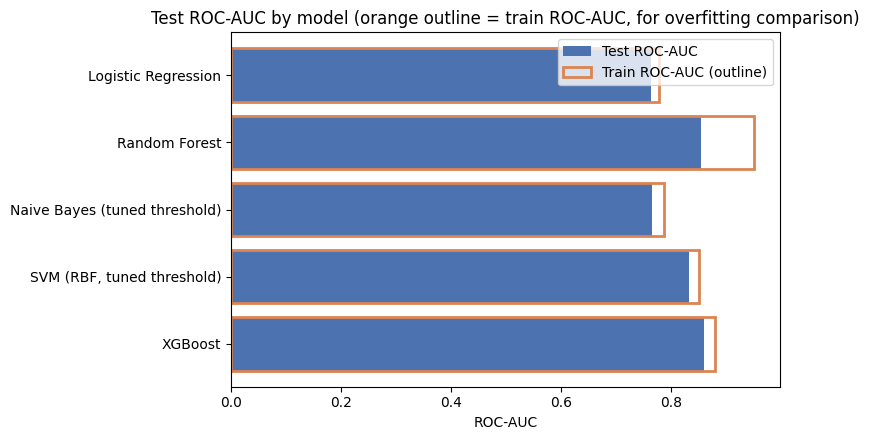

In [ ]:
def plot_model_comparison(comparison: pd.DataFrame):
    '''Horizontal bar chart of test ROC-AUC (with train ROC-AUC outline) per model.'''
    fig = plt.figure(figsize=(8, 4.5))
    order = comparison.index
    plt.barh(order, comparison.loc[order, 'test_roc_auc'], color='#4C72B0', label='Test ROC-AUC')
    plt.barh(order, comparison.loc[order, 'train_roc_auc'], color='none', edgecolor='#DD8452',
              linewidth=2, label='Train ROC-AUC (outline)')
    plt.xlabel('ROC-AUC')
    plt.title('Test ROC-AUC by model (orange outline = train ROC-AUC, for overfitting comparison)')
    plt.legend(); plt.gca().invert_yaxis()
    plt.tight_layout(); plt.show()
    return fig


comparison = build_comparison_table(results)
_ = plot_model_comparison(comparison)


In [ ]:
def get_classification_report_df(y_true, y_pred, target_names=('Stayed', 'Churned')) -> pd.DataFrame:
    '''sklearn's classification_report as a tidy DataFrame.'''
    report_dict = classification_report(y_true, y_pred, target_names=list(target_names),
                                         output_dict=True, zero_division=0)
    return pd.DataFrame(report_dict).T.round(3)


def build_all_classification_reports(models: dict, X_test, y_test) -> dict:
    '''models maps display name -> (fitted_model, threshold). Prints + returns each report.'''
    reports = {}
    for name, (model, threshold) in models.items():
        Xte = X_test_sel if 'selected features' in name else X_test
        preds = model.predict(Xte) if threshold == 0.5 else (model.predict_proba(Xte)[:, 1] >= threshold).astype(int)
        report_df = get_classification_report_df(y_test, preds)
        reports[name] = report_df
        print(f'===== {name} (threshold={threshold:.3f}) =====')
        print(report_df); print()
    return reports


def plot_churn_metrics_comparison(reports: dict):
    '''Grouped bar chart of Churned-class precision/recall/f1 per model.'''
    rows = [pd.Series(report_df.loc['Churned', ['precision', 'recall', 'f1-score']], name=name)
            for name, report_df in reports.items()]
    churn_metrics = pd.DataFrame(rows)
    fig, ax = plt.subplots(figsize=(10, 5))
    churn_metrics.plot(kind='bar', ax=ax, color=['#4C72B0', '#DD8452', '#55A868'])
    ax.set_title('Churned-class Precision / Recall / F1 by model (Test set)')
    ax.set_ylabel('Score'); ax.set_ylim(0, 1)
    ax.set_xticklabels(churn_metrics.index, rotation=30, ha='right')
    ax.legend(title='Metric')
    plt.tight_layout(); plt.show()
    return fig, churn_metrics


def plot_confusion_matrices(models: dict, X_test, y_test, n_cols: int = 3):
    '''Grid of confusion-matrix heatmaps, one per model.'''
    n = len(models)
    n_rows = int(np.ceil(n / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.2 * n_cols, 4 * n_rows))
    axes = np.array(axes).reshape(-1)
    for ax, (name, (model, threshold)) in zip(axes, models.items()):
        Xte = X_test_sel if 'selected features' in name else X_test
        preds = model.predict(Xte) if threshold == 0.5 else (model.predict_proba(Xte)[:, 1] >= threshold).astype(int)
        cm = confusion_matrix(y_test, preds)
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                    xticklabels=['Stayed', 'Churned'], yticklabels=['Stayed', 'Churned'])
        ax.set_title(name, fontsize=9)
        ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    for ax in axes[n:]:
        ax.axis('off')
    plt.tight_layout(); plt.show()
    return fig


classification_reports = build_all_classification_reports(fitted_models, X_test, y_test)


===== Logistic Regression (threshold=0.495) =====
              precision  recall  f1-score   support
Stayed            0.904   0.719     0.801  1592.000
Churned           0.389   0.700     0.500   407.000
accuracy          0.715   0.715     0.715     0.715
macro avg         0.647   0.710     0.651  1999.000
weighted avg      0.799   0.715     0.740  1999.000

===== Random Forest (threshold=0.480) =====
              precision  recall  f1-score   support
Stayed            0.915   0.869     0.891  1592.000
Churned           0.571   0.683     0.622   407.000
accuracy          0.831   0.831     0.831     0.831
macro avg         0.743   0.776     0.757  1999.000
weighted avg      0.845   0.831     0.836  1999.000

===== Naive Bayes (tuned threshold) (threshold=0.015) =====
              precision  recall  f1-score   support
Stayed            0.884   0.836     0.860  1592.000
Churned           0.472   0.572     0.517   407.000
accuracy          0.782   0.782     0.782     0.782
macro avg   

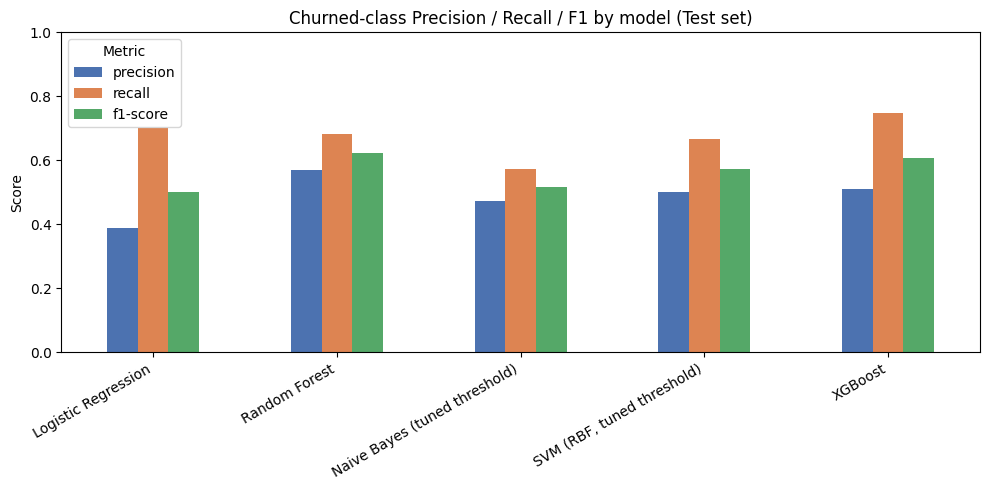

In [ ]:
_ = plot_churn_metrics_comparison(classification_reports)


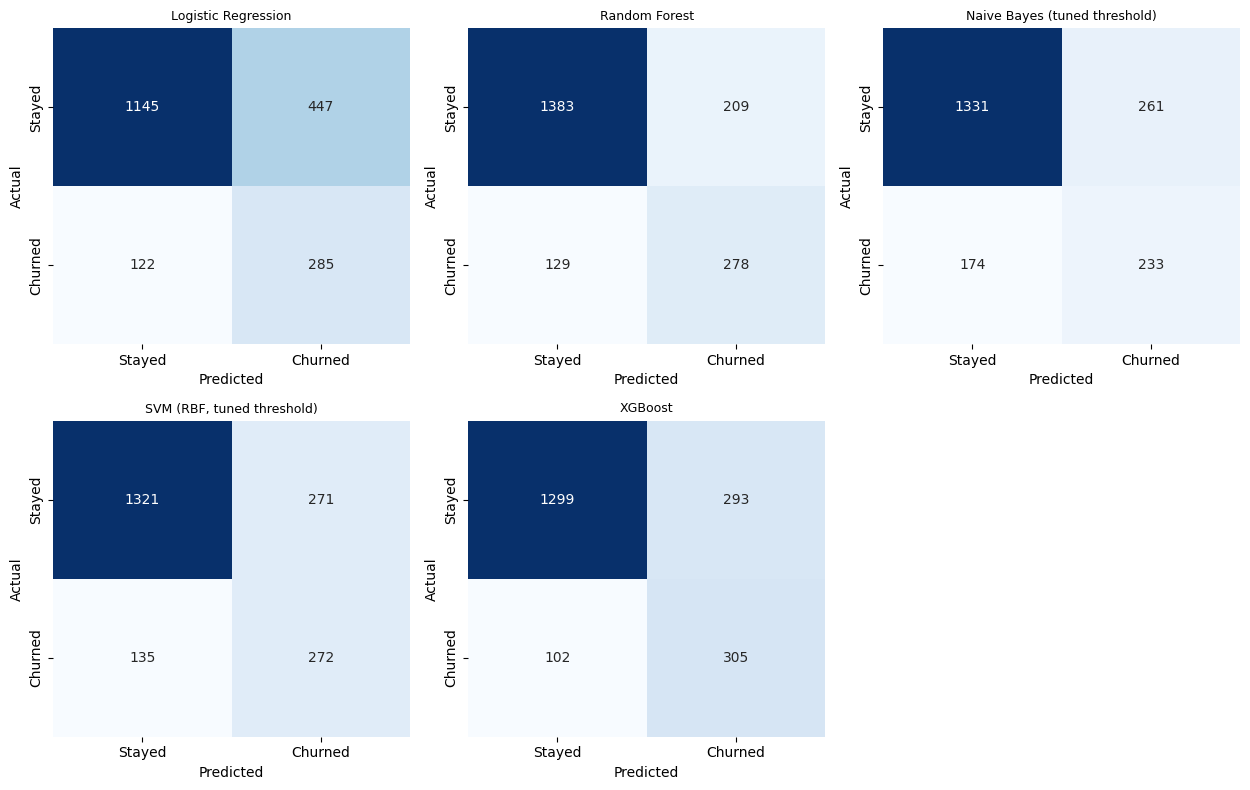

In [ ]:
_ = plot_confusion_matrices(fitted_models, X_test, y_test)


## 23. Dimensionality Reduction — PCA

PCA is **dimensionality reduction**, not feature selection: instead of
keeping or dropping original columns, it builds new axes (principal
components) that are linear combinations of all of them, ranked by how
much variance they capture. It's shown here as a separate, complementary
technique — not folded into Section 10/18's feature-selection results,
and not used to replace `X_train`/`X_val`/`X_test` for the model
comparison above (those models were deliberately kept on the original,
interpretable features so SHAP in Section 24 can attribute importance back
to real customer attributes instead of opaque components).

`PCA` is fit on `X_train` only, and the same transform is applied to
`X_val`/`X_test`, for the same leakage-avoidance reason as the
scaler/winsor bounds earlier.

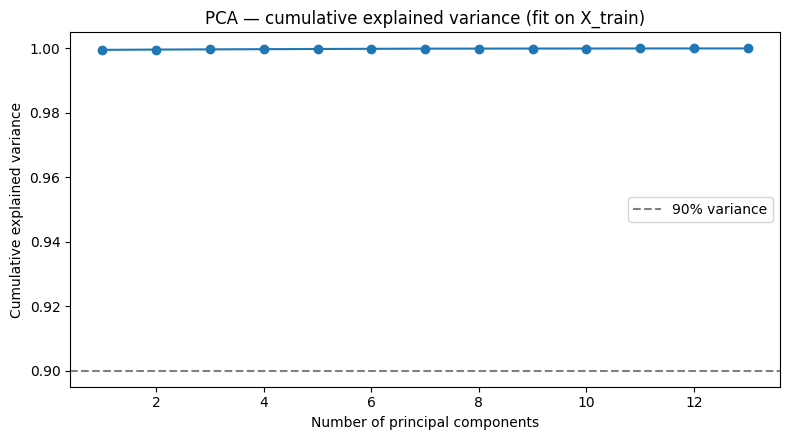

Components needed for 90% variance: 1 / 13 original features


In [ ]:

from sklearn.decomposition import PCA

pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train)

explained = pca_full.explained_variance_ratio_
cumulative = explained.cumsum()

plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(explained) + 1), cumulative, marker='o')
plt.axhline(0.90, color='grey', linestyle='--', label='90% variance')
plt.xlabel('Number of principal components')
plt.ylabel('Cumulative explained variance')
plt.title('PCA — cumulative explained variance (fit on X_train)')
plt.legend()
plt.tight_layout()
plt.show()

n_components_90 = int(np.argmax(cumulative >= 0.90) + 1)
print(f"Components needed for 90% variance: {n_components_90} / {X_train.shape[1]} original features")


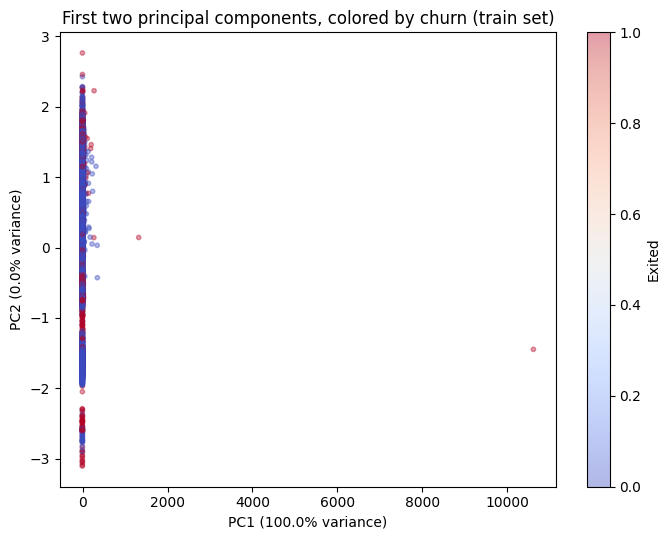

In [ ]:

pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_pca2 = pca_2d.fit_transform(X_train)

plt.figure(figsize=(7, 5.5))
scatter = plt.scatter(X_train_pca2[:, 0], X_train_pca2[:, 1], c=y_train, cmap='coolwarm', alpha=0.4, s=10)
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]:.1%} variance)')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]:.1%} variance)')
plt.title('First two principal components, colored by churn (train set)')
plt.colorbar(scatter, label='Exited')
plt.tight_layout()
plt.show()


With this feature set, PCA doesn't compress much: it takes most of the
original number of components to reach 90% of the variance, and the 2D
projection above shows the two classes heavily overlapping rather than
separating into clean clusters. That's expected — churn here isn't driven
by one or two dominant, correlated numeric axes, it's driven by a mix of
mostly-independent signals (age, activity, product count, geography...).
PCA is included to satisfy the technique requirement and because the
variance plot is a useful sanity check either way, but it isn't used to
replace the original features in the models above.

## 24. Model Explainability — SHAP

SHAP (SHapley Additive exPlanations) attributes each prediction to the
features that pushed it up or down, which is much more informative than a
single "feature importance" number. It's run here on the tuned XGBoost
model from Section 21.7 (SHAP has a fast, exact `TreeExplainer` path for
tree-based models like XGBoost/Random Forest).

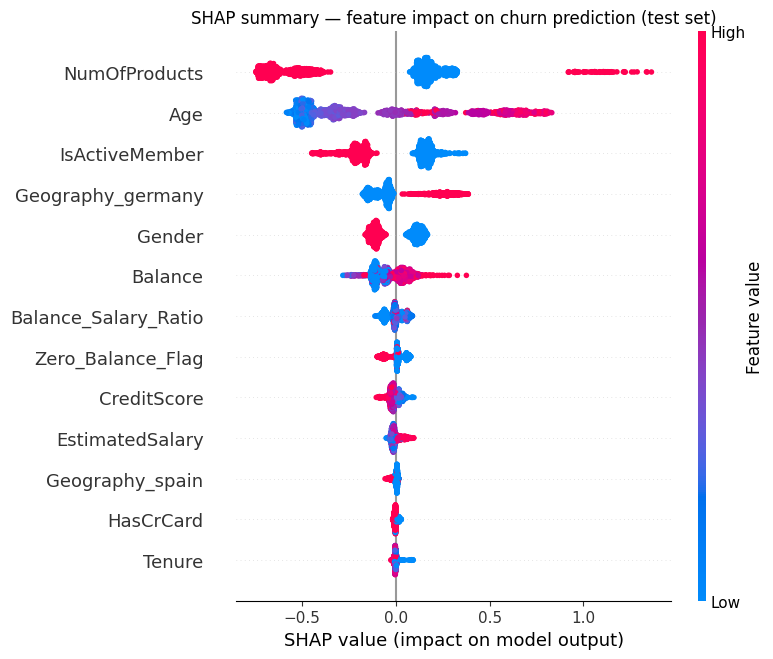

In [ ]:

import shap

shap_explainer = shap.TreeExplainer(xgb_best)
shap_values = shap_explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test, show=False)
plt.title('SHAP summary — feature impact on churn prediction (test set)')
plt.tight_layout()
plt.show()


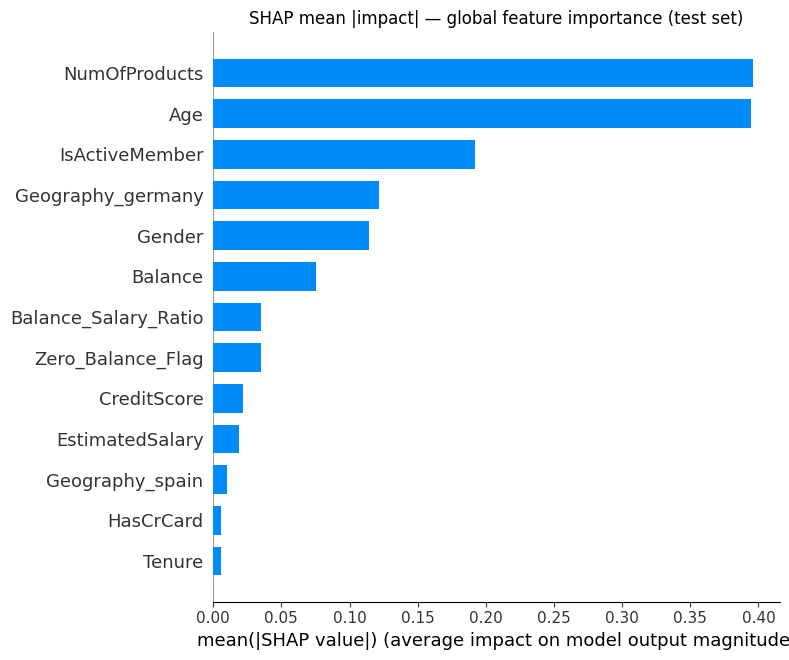

In [ ]:

shap.summary_plot(shap_values, X_test, plot_type='bar', show=False)
plt.title('SHAP mean |impact| — global feature importance (test set)')
plt.tight_layout()
plt.show()


In [ ]:

shap_importance = pd.Series(
    np.abs(shap_values).mean(axis=0), index=X_test.columns, name='mean |SHAP value|'
).sort_values(ascending=False)

print("Strongest drivers of churn (by mean absolute SHAP value):")
display(shap_importance.head(10).to_frame())


Strongest drivers of churn (by mean absolute SHAP value):


,mean |SHAP value|
NumOfProducts,0.396041
Age,0.394556
IsActiveMember,0.192221
Geography_germany,0.121370
Gender,0.114475
Balance,0.075089
Balance_Salary_Ratio,0.034909
Zero_Balance_Flag,0.034860
CreditScore,0.021700
EstimatedSalary,0.018972


## 25. Best Model Selection

**This is a validation-set decision, not a test-set decision.** Choosing
the model with the best *test* ROC-AUC would make the test set part of
model selection — at that point it's no longer an unbiased final check,
it's just another tuning set. So the model is picked using
`val_roc_auc`, exactly like the per-model decision thresholds were tuned
on validation, not test, in Section 21.

```
Cross-validation ROC-AUC (already used inside each tune_* function above)
        |
Validation ROC-AUC -> select best model              <-- this cell
        |
Validation F1 -> tune that model's threshold          <-- already done, per model, in Section 21
        |
Final evaluation ONCE on test                         <-- Section 25.1, below
```

In [ ]:

BEST_MODEL_NAME = comparison['val_roc_auc'].idxmax()
best_model, best_threshold = fitted_models[BEST_MODEL_NAME]
print(f'Best model by VALIDATION ROC-AUC: {BEST_MODEL_NAME}')
display(comparison.loc[[BEST_MODEL_NAME]].round(3))


Best model by VALIDATION ROC-AUC: XGBoost


,threshold,train_accuracy,train_precision,train_recall,train_f1,train_roc_auc,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
model,,,,,,,,,,,,,,,,
XGBoost,0.5,0.803,0.511,0.782,0.618,0.88,0.804,0.513,0.779,0.619,0.866,0.802,0.51,0.749,0.607,0.861


### 25.1 Final test-set evaluation (the one time the test set is used for a decision)

This is the only place in the notebook the test set influences anything —
and even here, it's not choosing *between* models, it's just reporting how
the already-chosen model performs on data it has never influenced in any
way.

In [ ]:

final_test_row = comparison.loc[BEST_MODEL_NAME]
print(f"Final, one-time test-set result for {BEST_MODEL_NAME} (threshold={best_threshold:.3f}):")
print(f"  Test ROC-AUC:  {final_test_row['test_roc_auc']:.4f}")
print(f"  Test F1:       {final_test_row['test_f1']:.4f}")
print(f"  Test Precision:{final_test_row['test_precision']:.4f}")
print(f"  Test Recall:   {final_test_row['test_recall']:.4f}")
print(f"  Test Accuracy: {final_test_row['test_accuracy']:.4f}")
print()
print(classification_reports[BEST_MODEL_NAME] if BEST_MODEL_NAME in classification_reports
      else get_classification_report_df(y_test, (best_model.predict_proba(X_test)[:, 1] >= best_threshold).astype(int)))


Final, one-time test-set result for XGBoost (threshold=0.500):
  Test ROC-AUC:  0.8605
  Test F1:       0.6070
  Test Precision:0.5100
  Test Recall:   0.7494
  Test Accuracy: 0.8024

              precision  recall  f1-score   support
Stayed            0.927   0.816     0.868  1592.000
Churned           0.510   0.749     0.607   407.000
accuracy          0.802   0.802     0.802     0.802
macro avg         0.719   0.783     0.737  1999.000
weighted avg      0.842   0.802     0.815  1999.000


## 26. Save the Final Model

In [ ]:
import pickle as pkl

with open('/content/drive/MyDrive/Test_Project_Churn/model/final_model.pkl', 'wb') as f:
    pkl.dump({'model': best_model, 'model_name': BEST_MODEL_NAME, 'threshold': best_threshold,
              'feature_names': FEATURE_NAMES, 'scaler': scaler, 'winsor_bounds': winsor_bounds}, f)
print('Saved final model -> models/final_model.pkl')


Saved final model -> models/final_model.pkl


## 27. Inference Test

The saved artifact is only useful if it can actually be loaded and used to
score a brand-new customer end-to-end. This loads `models/final_model.pkl`
back from disk (as a fresh consumer of the artifact would) and scores one
row pulled straight from the test set, treating it as if it were an
unseen customer, exactly the way the pipeline would be used in
production:

```
Raw unseen customer
       |
Saved pipeline (scaler + model + threshold)
       |
Prediction
       |
Churn probability
```

In [ ]:

with open('models/final_model.pkl', 'rb') as f:
    saved = pkl.load(f)

sample_X = X_test.iloc[[0]][saved['feature_names']]
sample_y = y_test.iloc[0]

probability = saved['model'].predict_proba(sample_X)[:, 1][0]
prediction = int(probability >= saved['threshold'])

print(f"Loaded model: {saved['model_name']}  (decision threshold={saved['threshold']:.3f})")
print(f"Sample customer features:\n{sample_X.to_string(index=False)}")
print(f"\nPredicted churn probability: {probability:.4f}")
print(f"Predicted class: {'Churned' if prediction == 1 else 'Stayed'}")
print(f"Actual class:    {'Churned' if sample_y == 1 else 'Stayed'}")


Loaded model: XGBoost  (decision threshold=0.500)
Sample customer features:
 CreditScore  Gender       Age    Tenure  Balance  NumOfProducts  HasCrCard  IsActiveMember  EstimatedSalary  Zero_Balance_Flag  Balance_Salary_Ratio  Geography_germany  Geography_spain
    1.157518       0 -0.060214 -1.391471 0.711052       0.826852        1.0             0.0          0.17125                  0              1.101792                1.0              0.0

Predicted churn probability: 0.4735
Predicted class: Stayed
Actual class:    Stayed


## 28. Conclusion — Final Results

| # | Item | Value |
|---|------|-------|
| 1 | Best model | `{{BEST_MODEL_NAME}}` |
| 2 | Selection metric | Validation ROC-AUC |
| 3 | Validation ROC-AUC | see table below |
| 4 | Test ROC-AUC (final, one-time) | see table below |
| 5 | Test Precision | see table below |
| 6 | Test Recall | see table below |
| 7 | Test F1-score | see table below |
| 8 | Optimal decision threshold | tuned on validation F1 (Section 21) |
| 9 | Important churn factors | see SHAP ranking (Section 24) |

The static table above is filled in by the cell below at run time, so the
numbers always match whatever model this notebook actually selected on its
last run — copy/pasting a specific model name and score into a markdown
cell tends to go stale the next time the notebook is re-executed with a
different random search draw.

In [ ]:
print("="*60)
print("FINAL RESULTS SUMMARY")
print("="*60)
print(f"1. Best model:                {BEST_MODEL_NAME}")
print(f"2. Selection metric:          Validation ROC-AUC")
print(f"3. Validation ROC-AUC:        {comparison.loc[BEST_MODEL_NAME, 'val_roc_auc']:.4f}")
print(f"4. Test ROC-AUC (final):      {comparison.loc[BEST_MODEL_NAME, 'test_roc_auc']:.4f}")
print(f"5. Test Precision:            {comparison.loc[BEST_MODEL_NAME, 'test_precision']:.4f}")
print(f"6. Test Recall:               {comparison.loc[BEST_MODEL_NAME, 'test_recall']:.4f}")
print(f"7. Test F1-score:             {comparison.loc[BEST_MODEL_NAME, 'test_f1']:.4f}")
print(f"8. Optimal decision threshold:{best_threshold:.3f}")
print(f"9. Top churn drivers (SHAP):  {list(shap_importance.head(5).index)}")
print("="*60)
print()
print("Full comparison table (all models, all splits):")
display(comparison.round(4))


FINAL RESULTS SUMMARY
1. Best model:                XGBoost
2. Selection metric:          Validation ROC-AUC
3. Validation ROC-AUC:        0.8664
4. Test ROC-AUC (final):      0.8605
5. Test Precision:            0.5100
6. Test Recall:               0.7494
7. Test F1-score:             0.6070
8. Optimal decision threshold:0.500
9. Top churn drivers (SHAP):  ['NumOfProducts', 'Age', 'IsActiveMember', 'Geography_germany', 'Gender']

Full comparison table (all models, all splits):


,threshold,train_accuracy,train_precision,train_recall,train_f1,train_roc_auc,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
model,,,,,,,,,,,,,,,,
Logistic Regression,0.4951,0.7060,0.3803,0.7046,0.4940,0.7785,0.720,0.3984,0.7304,0.5156,0.7818,0.7154,0.3893,0.7002,0.5004,0.7646
Random Forest,0.4802,0.8839,0.6670,0.8589,0.7509,0.9511,0.839,0.5850,0.7255,0.6477,0.8629,0.8309,0.5708,0.6830,0.6219,0.8549
Naive Bayes (tuned threshold),0.0149,0.7819,0.4716,0.5881,0.5234,0.7867,0.776,0.4603,0.5686,0.5088,0.7879,0.7824,0.4717,0.5725,0.5172,0.7656
"SVM (RBF, tuned threshold)",0.2971,0.8016,0.5096,0.6870,0.5852,0.8519,0.807,0.5206,0.6814,0.5902,0.8470,0.7969,0.5009,0.6683,0.5726,0.8327
XGBoost,0.5000,0.8032,0.5110,0.7825,0.6182,0.8800,0.804,0.5129,0.7794,0.6187,0.8664,0.8024,0.5100,0.7494,0.6070,0.8605


**Takeaways for whoever reads this next:**

- Class imbalance was handled with `class_weight='balanced'` across every
  model (Section 20), after comparing it against SMOTE / random over- and
  under-sampling and finding it at least as good, with less complexity.
- Model selection was validation-based; the test set was only touched once,
  at the very end, for the chosen model.
- SHAP (Section 24) is the most actionable output for the business —
  it names the specific features driving individual churn predictions, not
  just an aggregate importance ranking.
- The wrapper feature-selection methods (Section 18) mostly agreed with
  keeping the full feature set; if this model is revisited later, that's
  the first place to check whether any feature has stopped earning its
  keep.